# Projet final 5MLDE — Industrialiser un projet de Machine Learning

## Prévision de la demande de vélos en libre-service : une chaîne MLOps de bout en bout

**Auteur :** Rania Chanoun
**Données :** UCI Bike Sharing Dataset (Capital Bikeshare, Washington D.C., 2011-2012)
**Outils :** Python · scikit-learn · MLflow · Prefect · FastAPI · SQLite · Streamlit · Locust · pytest

---

Ce notebook sert de **fil conducteur et de démonstration** du projet. Il ne contient pas la logique métier : tout le code vit dans le paquet `src/bikeml/` et s'exécute en ligne de commande (`python -m bikeml ...`). Le notebook se contente d'appeler ces commandes, d'afficher les résultats et d'expliquer, étape par étape, ce qui se passe et pourquoi.

Autrement dit : **on peut supprimer ce notebook, le projet fonctionne toujours.** C'est une exigence du sujet (« le fonctionnement ne dépend pas d'un notebook »).

## Exécution sur Google Colab

Le notebook fonctionne tel quel sur **Google Colab** (et aussi en local). Marche à suivre :

1. Dans Colab : *Fichier → Importer un notebook* et choisir ce fichier `.ipynb`.
2. Exécuter **la première cellule de code ci-dessous**. Elle demande le fichier **`velo-mlops.zip`** (le dépôt du projet), le décompresse dans `/content/velo-mlops` et installe les dépendances manquantes.
   - Si le zip est déjà dans Google Drive, le placer à la racine de *Mon Drive* : il sera trouvé automatiquement après l'autorisation d'accès.
3. À la fin de l'installation, la cellule **redémarre la session une seule fois** (Colab affiche alors « La session a planté » ou « redémarrée » : c'est voulu, pour charger les nouvelles versions des bibliothèques).
4. Ensuite : *Exécution → Tout exécuter*. La première cellule détecte que tout est prêt et ne refait rien. L'exécution complète prend une dizaine de minutes (dont 3 à 4 pour les tests de charge).

**À savoir :** l'espace de travail Colab est effacé à la déconnexion. La dernière cellule du notebook permet, si on le souhaite, de sauvegarder les résultats (registre MLflow, traces, rapports) dans Google Drive.

In [1]:
# Préparation de l'environnement Colab (sans effet en exécution locale)
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DEPENDANCES = ["mlflow>=3.1,<4", "prefect>=3.1,<4", "fastapi>=0.110", "uvicorn>=0.29",
               "prometheus-client>=0.20", "locust>=2.20", "streamlit>=1.50"]

if IN_COLAB:
    projet = Path("/content/velo-mlops")
    if not (projet / "pyproject.toml").exists():
        archive = Path("/content/velo-mlops.zip")
        if not archive.exists():
            try:
                from google.colab import drive
                drive.mount("/content/drive")
                candidat = Path("/content/drive/MyDrive/velo-mlops.zip")
                if candidat.exists():
                    archive = candidat
            except Exception:
                pass
        if not archive.exists():
            from google.colab import files
            print("Sélectionner le fichier velo-mlops.zip :")
            archive = Path("/content") / next(iter(files.upload()))
        with zipfile.ZipFile(archive) as zf:
            zf.extractall("/content")
        print("Projet décompressé dans", projet)

    marqueur = Path("/content/.velo_mlops_installe")
    if not marqueur.exists():
        print("Installation des dépendances (1 à 2 minutes)...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *DEPENDANCES], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(projet), "--no-deps"], check=True)
        marqueur.touch()
        print("Installation terminée : redémarrage de la session. Lancer ensuite « Exécution > Tout exécuter ».")
        os.kill(os.getpid(), 9)
    print("Environnement Colab prêt.")
else:
    print("Exécution locale : installation décrite dans le README (requirements.txt).")

Exécution locale : installation décrite dans le README (requirements.txt).


## Sommaire

0. [Objectif et démarche](#0)
1. [Architecture et choix techniques](#1)
2. [Installation et reproductibilité](#2)
3. [Données : provenance, téléchargement, rejeu par lots](#3)
4. [Contrôles qualité bloquants](#4)
5. [Modèle et préparation des variables](#5)
6. [Traçabilité MLflow et règles de mise en service](#6)
7. [Orchestration : premier passage du pipeline](#7)
8. [Simulation du flux de données sur 2012 et déclenchement automatique](#8)
9. [Incident contrôlé n°1 : un lot de données invalide](#9)
10. [API de prédiction, persistance et feedbacks](#10)
11. [Incident contrôlé n°2 : dépendance indisponible](#11)
12. [Retour à une version précédente (rollback)](#12)
13. [Tests de charge et dimensionnement](#13)
14. [Supervision : le dashboard](#14)
15. [Tests automatisés](#15)
16. [Bilan, limites et pistes d'amélioration](#16)

<a id="0"></a>
## 0. Objectif et démarche

### Le sujet
Un opérateur de vélos en libre-service doit savoir **combien de vélos seront loués dans l'heure** pour répartir sa flotte entre les stations et planifier ses équipes. On construit un modèle de régression qui prédit le nombre de locations horaires (`cnt`) à partir du calendrier (heure, jour, mois, jour férié...) et de la météo (température, humidité, vent, situation météo).

### Ce qui est évalué
Le sujet le dit clairement : **la performance du modèle n'est pas évaluée**. Ce qui compte, c'est la chaîne opérationnelle autour du modèle : qu'elle soit reproductible, traçable, robuste aux incidents, supervisée et dimensionnée à partir de mesures. Le modèle choisi est donc volontairement simple (un gradient boosting de scikit-learn) ; tout l'effort porte sur l'industrialisation.

### Correspondance avec la grille d'évaluation

| Critère | Où le trouver dans le projet |
|---|---|
| Qualité du code (20 %) | paquet `src/bikeml/` découpé par responsabilité, configuration unique `configs/config.yaml`, 33 tests `tests/` |
| Reproductibilité (10 %) | `requirements.txt` figé, `pip install -e .`, téléchargement vérifié par empreinte SHA-256, graine aléatoire fixée, sections 2-3 |
| Intégration du cycle MLOps (20 %) | ingestion → validation → entraînement → registre → API → feedback → supervision, sections 7-10 |
| Fiabilité et traçabilité (20 %) | contrôles bloquants + quarantaine, alertes, suivi des exécutions, MLflow, rollback, sections 4, 6, 9, 11, 12 |
| Exploitation du service (20 %) | API FastAPI validée, traces SQLite, feedbacks, métriques Prometheus, dashboard, sections 10 et 14 |
| Dimensionnement (10 %) | campagne Locust multi-configurations, mesure CPU/RAM, recommandation chiffrée, section 13 |

### Couverture des fonctionnalités attendues par le sujet

| Fonctionnalité demandée | Comment elle est couverte | Section |
|---|---|---|
| Code et reproductibilité | paquet `src/bikeml/` modulaire, `configs/config.yaml`, `requirements.txt` figé, 33 tests pytest, README ; le notebook n'est qu'une vitrine | 1, 2, 15 |
| Données | téléchargement reproductible (SHA-256 + fiche de provenance), 8 contrôles qualité **bloquants** avant tout prétraitement, quarantaine | 3, 4, 9 |
| Orchestration | flow Prefect (validation → entraînement → promotion → notification), déclenchement automatique (`watch` / `serve`), suivi `pipeline_runs`, retries, hook d'échec, alertes | 7, 8 |
| Traçabilité et modèles | MLflow : données (empreinte), paramètres, métriques, artefacts ; registre versionné, tags, alias `@champion`, règles de promotion, rollback | 6, 8, 12 |
| API de prédiction | FastAPI : `/predict` (en ligne) et `/predict/batch` (lot), validation Pydantic (422), erreurs 413/404/409/503, version servie dans chaque réponse | 10, 11 |
| Retours et persistance | `/feedback` ; tables SQLite `requests`, `predictions`, `feedback` (version, durée, erreur) | 10 |
| Charge et déploiement | Locust, 2 configurations × 3 niveaux de charge, CPU/RAM mesurés, recommandation chiffrée | 13 |
| Supervision | dashboard Streamlit (traitements, modèles, service, qualité, charge) + `/metrics` Prometheus | 14 |
| Démonstration de bout en bout | fonctionnement nominal (13 lots) + incident n°1 (lot invalide) + incident n°2 (registre indisponible) | 7-12 |


<a id="1"></a>
## 1. Architecture et choix techniques

### Vue d'ensemble

```
                 ┌──────────────────────────── PIPELINE (Prefect) ────────────────────────────┐
  UCI / miroir   │                                                                             │
  ──────────►  data/raw ──► data/batches ──► data/incoming ──► [1] validation ──┬─► data/quarantine + ALERTE
   (setup)       (sha256 +      (rejeu :       (un fichier =        (bloquante)   │
                 provenance)    1 lot/mois)     un lot arrive)                    ▼
                 │                                                     data/accepted
                 │                                                           │
                 │                       [2] entraînement (toutes données acceptées, split temporel)
                 │                                                           │
                 │                 MLflow : paramètres, métriques, données, artefact, version
                 │                                                           │
                 │            [3] évaluation challenger vs champion vs référence naïve (même période)
                 │                         │ promu → alias @champion          │ rejeté → tag + alerte
                 │                         ▼                                  │
                 │             [4] notification de l'API (/admin/reload)      │
                 └────────────────────────────────────────────────────────────────────────────┘
                                           │
                                           ▼
                ┌──────────── API FastAPI ────────────┐         ┌──────── Supervision ────────┐
   clients ───► │ /predict  /predict/batch  /feedback │ ──────► │ data/ops.db (SQLite)        │
                │ /health  /model  /admin/reload      │         │  pipeline_runs, alerts,     │
                │ /metrics (Prometheus)               │         │  requests, predictions,     │
                └─────────────────────────────────────┘         │  feedback                   │
                                                                │ Dashboard Streamlit         │
                                                                └─────────────────────────────┘
```

### Pourquoi ces outils

| Besoin | Outil retenu | Justification | Alternative écartée |
|---|---|---|---|
| Orchestration | **Prefect 3** | Flows en Python pur, retries et hooks d'échec déclaratifs, fonctionne en local sans serveur (mode éphémère), UI optionnelle | Airflow : trop lourd pour un poste local (scheduler + base + webserver) |
| Suivi d'expériences et registre | **MLflow** | Standard du marché ; suivi des runs, artefacts et registre avec **alias** (`@champion`), parfait pour les règles de mise en service et le rollback | Fichiers pickle versionnés à la main : pas de traçabilité |
| Service | **FastAPI + uvicorn** | Validation d'entrée par Pydantic, documentation OpenAPI automatique (`/docs`), multi-workers pour le dimensionnement | Flask : validation à écrire soi-même |
| Persistance des traces | **SQLite (mode WAL)** | Aucun service à installer, requêtable en SQL, suffisant pour un service local | PostgreSQL : surdimensionné ici |
| Supervision | **Streamlit** + métriques **Prometheus** | Dashboard en quelques dizaines de lignes branché directement sur la base ; `/metrics` reste compatible Grafana si besoin | Grafana + Prometheus : deux services de plus à faire tourner |
| Tests de charge | **Locust** | Scénarios écrits en Python, mode headless avec export CSV exploitable automatiquement | JMeter : configuration XML lourde |
| Tests | **pytest** | Fixtures pour isoler chaque test dans un dossier temporaire | — |

Tout tourne en local, sans service payant ni compte cloud.

### Organisation du dépôt

```
velo-mlops/
├── configs/config.yaml          # TOUTE la configuration (chemins, règles qualité, hyperparamètres, seuils...)
├── src/bikeml/
│   ├── __main__.py              # interface en ligne de commande (python -m bikeml ...)
│   ├── config.py                # chargement de la configuration
│   ├── data/ingest.py           # téléchargement, provenance, découpage en lots, simulation d'arrivée
│   ├── data/validate.py         # contrôles qualité bloquants
│   ├── model/train.py           # variables, modèle, référence naïve, journalisation MLflow
│   ├── model/registry.py        # règles de promotion, alias, rollback
│   ├── orchestration/steps.py   # étapes du pipeline (Python pur, testables)
│   ├── orchestration/flows.py   # flow Prefect + déclenchement automatique
│   ├── api/                     # API FastAPI (schémas, service du modèle, endpoints)
│   └── monitoring/              # base des traces (SQLite) et alertes
├── dashboard/app.py             # dashboard Streamlit
├── load_tests/locustfile.py     # scénario de charge
├── scripts/run_load_tests.py    # campagne de charge + recommandation
├── tests/                       # tests automatisés
├── notebooks/                   # ce notebook (démonstration)
├── README.md  SYNTHESE_OPS.md  Makefile  requirements.txt  pyproject.toml
```

Le code suit une règle simple : **une étape = un module = une responsabilité**. Les étapes du pipeline (`steps.py`) sont de simples fonctions Python ; Prefect (`flows.py`) ne fait que les enchaîner. On peut ainsi tester chaque étape sans démarrer d'orchestrateur.

<a id="2"></a>
## 2. Installation et reproductibilité

### Installation (à faire une seule fois)

Sur **Google Colab**, c'est la première cellule du notebook qui s'en charge (dépendances manquantes installées par `pip`, les autres bibliothèques étant déjà fournies par Colab).

En **local**, dans un terminal :

```bash
python -m venv .venv
source .venv/bin/activate          # Windows : .venv\Scripts\activate
pip install -r requirements.txt    # versions figées, testées ensemble
pip install -e . --no-deps         # installe le paquet bikeml en mode éditable
```

### Ce qui garantit la reproductibilité
- **Dépendances figées** dans `requirements.txt` (versions exactes) et déclarées de façon plus souple dans `pyproject.toml`.
- **Configuration séparée du code** : `configs/config.yaml` contient chemins, règles de validation, hyperparamètres, seuils de promotion et paramètres de charge. Aucune valeur « magique » dans le code.
- **Pas de secret dans le dépôt** : l'URL du webhook d'alerte ou d'un éventuel serveur MLflow passe par des variables d'environnement (modèle fourni dans `.env.example`).
- **Pas de données volumineuses dans le dépôt** : elles sont téléchargées par `python -m bikeml setup`, et leur intégrité est vérifiée par une empreinte SHA-256.
- **Graine aléatoire fixée** (`project.random_seed`) pour l'entraînement.
- **Rejeu déterministe** : les lots arrivent toujours dans le même ordre chronologique.

### Préparation du notebook
La cellule suivante définit quelques fonctions utilitaires : `run()` lance une commande `python -m bikeml ...` exactement comme on le ferait dans un terminal, et `sql()` lit la base des traces.

In [2]:
import json, os, sys, shutil, sqlite3, subprocess, time
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"   # messages d'information MLflow inutiles ici
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/velo-mlops")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
# les commandes lancées en sous-processus doivent aussi trouver le paquet
os.environ["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + os.environ.get("PYTHONPATH", "")
PY = sys.executable
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)


def run(*args, keep=None, tail=30):
    # Lance `python -m bikeml <args>` et affiche les lignes utiles de la sortie.
    proc = subprocess.run([PY, "-m", "bikeml", *args], capture_output=True, text=True, cwd=ROOT)
    lines = (proc.stdout + proc.stderr).splitlines()
    if keep:
        lines = [l for l in lines if any(k in l for k in keep)]
    if tail:
        print("\n".join(lines[-tail:]))
        print(f"--> code retour : {proc.returncode}")
    return proc.returncode


def sql(query):
    with sqlite3.connect(ROOT / "data" / "ops.db") as con:
        return pd.read_sql_query(query, con)


print("Environnement :", "Google Colab" if IN_COLAB else "local")
print("Racine du projet :", ROOT.name)
print("Python :", sys.version.split()[0])

Environnement : local
Racine du projet : velo-mlops
Python : 3.13.18


**Repartir d'un état vierge.** Pour que la démonstration soit rejouable à l'identique, on efface tout ce qui a pu être généré par une exécution précédente : données, registre MLflow, traces et rapports. C'est l'équivalent de `make reset`.

In [3]:
for p in ["data", "mlruns", "reports/validation", "reports/load_tests"]:
    shutil.rmtree(ROOT / p, ignore_errors=True)
(ROOT / "mlflow.db").unlink(missing_ok=True)
print("État remis à zéro.")

État remis à zéro.


<a id="3"></a>
## 3. Données : provenance, téléchargement, rejeu par lots

### 3.1 Provenance et conditions d'utilisation
- **Jeu de données :** *Bike Sharing Dataset*, Fanaee-T & Gama (2013), dépôt UCI Machine Learning Repository : <https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset>
- **Origine :** historique public du système Capital Bikeshare (Washington D.C.), enrichi de données météo et du calendrier des jours fériés.
- **Licence :** Creative Commons Attribution 4.0 (CC BY 4.0) : utilisation libre, y compris pour un projet académique, **à condition de citer la source** (citation enregistrée dans la fiche de provenance).
- **Contenu utilisé :** `hour.csv`, 17 379 lignes, une par heure du 1er janvier 2011 au 31 décembre 2012.
- **Données personnelles :** aucune ; les données sont agrégées par heure.

### 3.2 Téléchargement contrôlé
La commande `setup` :
1. télécharge l'archive depuis le site UCI ; si celui-ci est inaccessible, elle bascule sur un miroir public du **même fichier** ;
2. **vérifie l'empreinte SHA-256** du fichier obtenu : si elle ne correspond pas à celle attendue (fixée dans la configuration), le fichier est supprimé et la commande échoue. On est donc sûr de travailler sur exactement les mêmes données d'une machine à l'autre ;
3. écrit une **fiche de provenance** (`data/raw/PROVENANCE.json`) : source réellement utilisée, date, empreinte, licence, citation ;
4. prépare les lots de rejeu (voir 3.4).

La commande est idempotente : relancée, elle ne retélécharge pas un fichier déjà présent et valide.

In [4]:
run("setup")
print(json.dumps(json.loads((ROOT / "data/raw/PROVENANCE.json").read_text()), indent=2, ensure_ascii=False))

13 lots prêts dans data/batches
2026-11-18 10:38:19,692 INFO    bikeml.ingest - Téléchargement depuis https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip
2026-11-18 10:38:19,942 WARNING bikeml.ingest - Échec du téléchargement (https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip) : <urlopen error Tunnel connection failed: 403 Forbidden>
2026-11-18 10:38:19,942 INFO    bikeml.ingest - Téléchargement depuis https://raw.githubusercontent.com/deep-learning-with-pytorch/dlwpt-code-2e/main/data/p1ch4/bike-sharing-dataset/hour.csv
2026-11-18 10:38:20,490 INFO    bikeml.ingest - Fichier brut enregistré (data/raw/hour.csv, sha256=b03a2d02e8c1…)
2026-11-18 10:38:20,603 INFO    bikeml.ingest - 13 lots préparés dans data/batches
--> code retour : 0
{
  "dataset": "Bike Sharing Dataset (Fanaee-T & Gama, 2013)",
  "official_page": "https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset",
  "downloaded_from": "https://raw.githubusercontent.com/deep-learning-

### 3.3 Coup d'œil aux données
Avant de modéliser, deux graphiques suffisent à comprendre la structure du problème et à justifier les variables retenues.

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


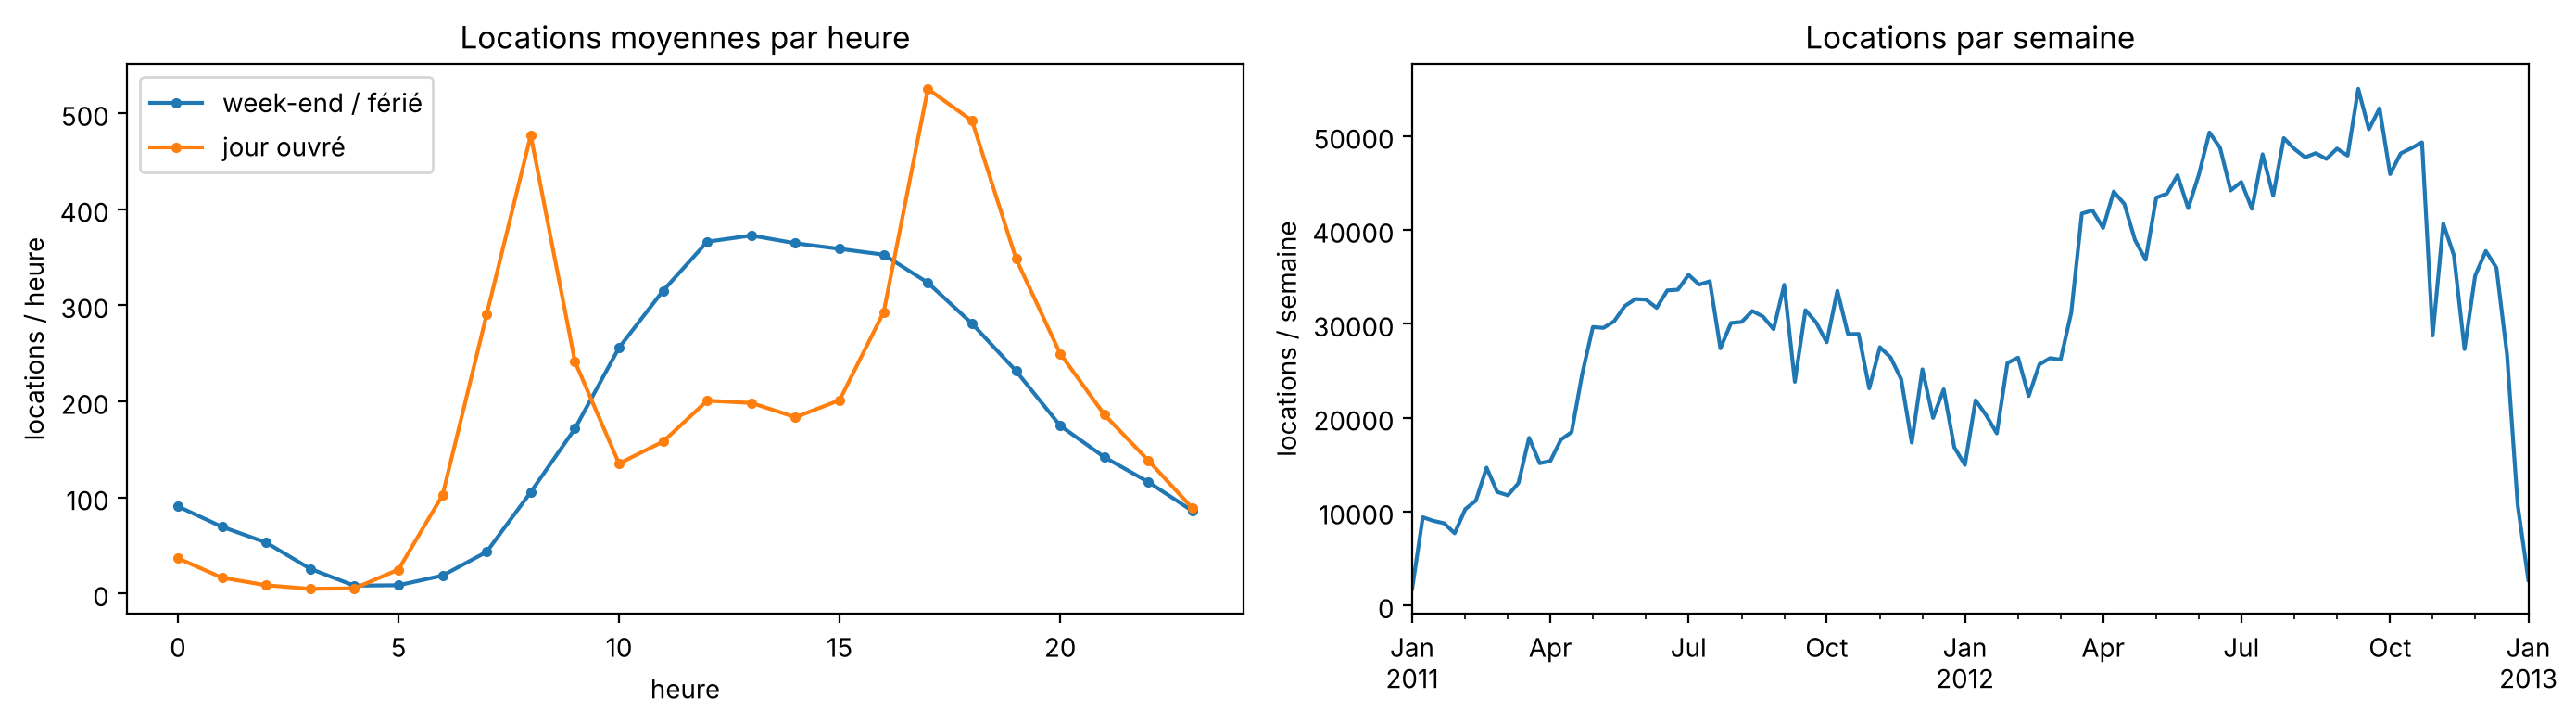

In [5]:
raw = pd.read_csv("data/raw/hour.csv", parse_dates=["dteday"])
print(raw.shape)
display(raw.head(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profile = raw.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
profile.columns = ["week-end / férié", "jour ouvré"]
profile.plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="Locations moyennes par heure", xlabel="heure", ylabel="locations / heure")
raw.set_index("dteday")["cnt"].resample("W").sum().plot(ax=axes[1])
axes[1].set(title="Locations par semaine", xlabel="", ylabel="locations / semaine")
plt.tight_layout()
plt.show()

**Ce qu'on en retient :**
- Le profil horaire est **totalement différent** entre jours ouvrés (deux pics : trajets domicile-travail à 8 h et 17-18 h) et week-ends (une bosse l'après-midi). Le modèle doit donc capter l'interaction *heure × jour ouvré* : un modèle à base d'arbres le fait naturellement.
- La demande est **saisonnière** (creux en hiver) et **en croissance** entre 2011 et 2012. Conséquence importante pour l'MLOps : un modèle entraîné sur le passé se dégrade si on ne le réentraîne pas, et **les erreurs ne sont comparables que sur une même période** (une erreur de 100 vélos en été n'a pas le même sens qu'en hiver). On retrouvera ce point dans les règles de promotion.

### 3.4 Rejeu de l'historique par lots
Le jeu de données est historique : il n'arrive pas « en continu ». Comme le sujet l'autorise, on **simule l'arrivée de nouvelles données** en rejouant l'historique par lots :

- **lot initial** `0000_initial.csv` : toute l'année 2011 (socle du premier modèle) ;
- puis **un lot par mois de 2012** (`2012-01.csv` ... `2012-12.csv`), livrés dans l'ordre chronologique.

Les lots préparés sont stockés dans `data/batches/`. Pour « livrer » un lot, la commande `release` le copie dans `data/incoming/` : ce dossier joue le rôle de la boîte de dépôt qu'alimenterait un système amont en production. C'est l'arrivée d'un fichier dans ce dossier qui déclenche le pipeline.

In [6]:
batches = sorted((ROOT / "data/batches").glob("*.csv"))
pd.DataFrame([{"lot": b.name, "lignes": sum(1 for _ in open(b)) - 1} for b in batches]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12
lot,0000_initial.csv,2012-01.csv,2012-02.csv,2012-03.csv,2012-04.csv,2012-05.csv,2012-06.csv,2012-07.csv,2012-08.csv,2012-09.csv,2012-10.csv,2012-11.csv,2012-12.csv
lignes,8645,741,692,743,718,744,720,744,744,720,708,718,742


<a id="4"></a>
## 4. Contrôles qualité bloquants

Avant tout prétraitement, chaque lot passe par `src/bikeml/data/validate.py`. Les règles sont décrites dans la section `validation` de la configuration :

| Contrôle | Règle | Pourquoi |
|---|---|---|
| `schema` | toutes les colonnes attendues sont présentes | un export amont modifié casserait l'entraînement |
| `volume` | au moins 100 lignes | un lot quasi vide signale une extraction ratée |
| `completude` | 0 % de valeurs manquantes | le jeu source est complet : un trou est une anomalie |
| `unicite` | pas de doublon sur (date, heure) | un doublon fausserait l'apprentissage et l'évaluation |
| `types` | les colonnes numériques ne contiennent que des nombres | une valeur texte (ex. « chaud ») n'est ni manquante ni hors bornes : sans ce contrôle elle ne serait vue qu'au plantage de l'entraînement |
| `bornes` | chaque variable dans son domaine (heure 0-23, température normalisée 0-1, comptages ≥ 0...) | détecte les erreurs de capteur ou de format |
| `coherence` | `casual + registered = cnt` | règle métier du jeu de données |
| `dates` | dates lisibles | indispensable au découpage temporel |

**Le contrôle est bloquant :** si une seule règle échoue, l'étape lève une `DataValidationError`. Le lot est déplacé en **quarantaine** (`data/quarantine/`), un **rapport détaillé** est écrit dans `reports/validation/`, une **alerte** est émise, et **l'entraînement n'a pas lieu**. Le modèle en service n'est donc jamais exposé à des données corrompues.

Vérifions le comportement directement sur un lot sain et sur une version volontairement abîmée :

In [7]:
from bikeml.config import get_config
from bikeml.data.validate import validate_batch

cfg = get_config()
lot_sain = pd.read_csv("data/batches/2012-01.csv")
rapport = validate_batch(lot_sain, cfg)
print("Lot sain conforme :", rapport.passed)
display(pd.DataFrame(rapport.to_dict()["checks"]))

lot_abime = lot_sain.copy()
lot_abime.loc[0:4, "hr"] = 31            # heures impossibles
lot_abime.loc[5:6, "temp"] = None        # valeurs manquantes
lot_abime["windspeed"] = lot_abime["windspeed"].astype(object)
lot_abime.loc[7, "windspeed"] = "fort"   # valeur non numérique
rapport = validate_batch(lot_abime, cfg)
print("Lot abîmé conforme :", rapport.passed)
display(pd.DataFrame(rapport.to_dict()["checks"]))

Lot sain conforme : True


,name,passed,detail
0,schema,True,ok
1,volume,True,741 lignes (min 100)
2,completude,True,taux max de manquants : 0.00%
3,unicite,True,"taux de doublons (date, heure) : 0.00%"
4,types,True,ok
5,bornes,True,ok
6,coherence,True,0 lignes où casual + registered != cnt
7,dates,True,0 dates illisibles


Lot abîmé conforme : False


,name,passed,detail
0,schema,True,ok
1,volume,True,741 lignes (min 100)
2,completude,False,taux max de manquants : 0.27%
3,unicite,False,"taux de doublons (date, heure) : 0.54%"
4,types,False,valeurs non numériques : {'windspeed': 1}
5,bornes,False,valeurs hors bornes : {'hr': 5}
6,coherence,True,0 lignes où casual + registered != cnt
7,dates,True,0 dates illisibles


<a id="5"></a>
## 5. Modèle et préparation des variables

Code : `src/bikeml/model/train.py`.

### Variables
- **Retenues :** `hr, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed` : l'heure, le type de jour et la météo.
- **Écartées volontairement :**
  - `casual` et `registered` : leur somme est exactement la cible. Les garder serait une **fuite de données** (le modèle « tricherait » et serait inutilisable en production, où ces valeurs ne sont pas connues à l'avance). Un test automatique vérifie qu'elles ne sont jamais utilisées ;
  - `yr` : l'année ne se généralise pas (en production, on ne voit que des années nouvelles) ;
  - `mnth` et `season` : à cause de la **forte croissance de la demande entre 2011 et 2012**, ces variables rattachent la prédiction au niveau du même mois de l'année précédente, et le modèle sous-estime alors systématiquement la demande. Ce choix a été fait à partir de l'expérience ci-dessous, pas a priori. L'effet saisonnier reste capté par la température et la météo ;
  - `instant`, `dteday` : identifiants temporels.

### Pondération par l'ancienneté
Pour suivre l'évolution de la demande (dérive progressive), chaque observation reçoit un poids qui **est divisé par deux tous les 30 jours d'ancienneté** (`recency_half_life_days` dans la configuration). Le modèle s'appuie ainsi surtout sur les semaines récentes, sans jeter l'historique.

### Modèle
`HistGradientBoostingRegressor` (scikit-learn), enveloppé dans un `TransformedTargetRegressor` :
- gère nativement les variables catégorielles (`weathersit`, la seule catégorielle conservée depuis le retrait de `season`) et les interactions (heure × jour ouvré) ;
- s'entraîne en quelques secondes sur un CPU ordinaire ;
- la cible est transformée en `log(1 + cnt)` car les comptages sont très asymétriques (beaucoup d'heures creuses, quelques pics) ; la prédiction est ramenée dans l'échelle d'origine et bornée à 0.

### Évaluation
- **Découpage temporel**, jamais aléatoire : les 28 derniers jours disponibles servent d'évaluation, tout ce qui précède sert à l'entraînement. On imite ainsi l'usage réel : prédire le futur à partir du passé. Un découpage aléatoire mélangerait des heures voisines entre apprentissage et test et donnerait un score trop optimiste.
- Métriques : **RMSE** (métrique de décision), MAE et R².
- **Référence naïve** : la moyenne historique par (heure, jour ouvré). Un modèle de ML n'a d'intérêt que s'il fait mieux que cette règle simple ; c'est une des conditions de mise en service.

### Expérience qui a guidé ces choix
On rejoue les 12 mois de 2012 : pour chaque mois, on entraîne sur tout ce qui précède les 28 derniers jours et on évalue sur ces 28 jours, exactement comme le fera le pipeline. On compare trois variantes et la référence naïve (RMSE, plus c'est bas, mieux c'est) :
- **A** : toutes les variables calendaires et météo, sans pondération ;
- **B** : sans `mnth` ni `season` ;
- **C** : B + pondération par l'ancienneté (configuration retenue).

In [8]:
import numpy as np
from bikeml.model.train import NaiveBaseline, build_model, evaluate, recency_weights, temporal_split

full = pd.read_csv("data/raw/hour.csv", parse_dates=["dteday"]).sort_values(["dteday", "hr"])
toutes = ["season", "mnth"] + cfg.model["features"]
variantes = {"A : toutes variables": (toutes, None),
             "B : sans mois/saison": (cfg.model["features"], None),
             "C : B + pondération": (cfg.model["features"], cfg.model["recency_half_life_days"])}

lignes = []
for mois in range(1, 13):
    fin = pd.Timestamp(2012, mois, 1) + pd.offsets.MonthEnd(0)
    train, test = temporal_split(full[full.dteday <= fin], cfg.model["holdout_days"])
    ligne = {"mois évalué": f"2012-{mois:02d}"}
    for nom, (feats, demi_vie) in variantes.items():
        c = dict(cfg, model={**cfg.model, "features": feats, "categorical": ["season", "weathersit"]})
        c = type(cfg)(c)
        m = build_model(c).fit(train[feats], train["cnt"], sample_weight=recency_weights(train, demi_vie))
        ligne[nom] = evaluate(m, test, c)["rmse"]
    ligne["référence naïve"] = evaluate(NaiveBaseline().fit(train, train["cnt"]), test, cfg)["rmse"]
    lignes.append(ligne)

exp = pd.DataFrame(lignes).set_index("mois évalué")
display(exp.round(1).T)
print("RMSE moyen :", exp.mean().round(1).to_dict())

mois évalué,2012-01,2012-02,2012-03,2012-04,2012-05,2012-06,2012-07,2012-08,2012-09,2012-10,2012-11,2012-12
A : toutes variables,105.5,100.1,151.2,129.0,102.7,115.4,132.1,123.0,139.7,139.4,110.5,84.8
B : sans mois/saison,72.9,73.6,117.4,116.2,103.5,109.3,120.0,101.4,123.6,134.3,118.2,95.4
C : B + pondération,54.3,53.4,109.7,73.5,74.8,55.0,77.1,54.5,73.4,80.6,87.3,80.6
référence naïve,57.1,58.2,135.3,152.0,157.9,164.2,150.1,156.1,181.8,155.3,87.6,110.7


RMSE moyen : {'A : toutes variables': 119.4, 'B : sans mois/saison': 107.1, 'C : B + pondération': 72.8, 'référence naïve': 130.5}


**Conclusion :** avec toutes les variables (A), le modèle fait *moins bien que la référence naïve* en début d'année 2012 : il a appris le niveau de janvier 2011, bien plus bas. Retirer le mois et la saison (B) corrige une partie du problème ; ajouter la pondération (C) donne le meilleur résultat sur **les 12 mois** (RMSE moyen 72.8 contre 130.5 pour la référence naïve) et bat la référence naïve chaque mois, de justesse en novembre (87.3 contre 87.6). C'est la configuration retenue dans `configs/config.yaml`.

C'est aussi une bonne illustration de l'intérêt des **règles de mise en service** : sans la comparaison systématique à une référence naïve, la variante A aurait été mise en production sans que personne ne remarque qu'elle était moins bonne qu'une simple moyenne.

Le modèle de production n'est pas entraîné « à la main » ici : c'est le pipeline qui s'en charge (section 7).

<a id="6"></a>
## 6. Traçabilité MLflow et règles de mise en service

### Ce qui est enregistré pour chaque entraînement (un *run* MLflow)
| Catégorie | Contenu |
|---|---|
| **Données** | lot déclencheur, nombre de lots utilisés, tailles train/évaluation, périodes couvertes, **empreinte SHA-256 des données d'entraînement** (tag `data_sha256`), liste des fichiers (`data_manifest.json`) |
| **Paramètres** | type de modèle, hyperparamètres, liste des variables, demi-vie de la pondération |
| **Métriques** | RMSE / MAE / R² en évaluation, les mêmes sur l'entraînement (détection de sur-apprentissage), et celles de la référence naïve |
| **Artefacts** | modèle sérialisé avec sa **signature** (schéma d'entrée) et un exemple d'entrée |
| **Contexte** | commit Git du code, identifiant du run de pipeline qui l'a produit |

Chaque modèle est **enregistré dans le registre** sous le nom `bike-demand`, ce qui lui donne un numéro de version.

### Conventions du registre
- **alias `@champion`** : la version servie par l'API. L'API ne connaît pas de numéro de version en dur, elle charge `models:/bike-demand@champion` ;
- **alias `@previous`** : le champion précédent, cible naturelle d'un retour arrière ;
- **tag `status`** sur chaque version : `champion`, `archived`, `rejected`, `rolled_back` ;
- **tag `decision`** : la justification de la décision, lisible par un humain.

### Règles de mise en service (`registry.decide_promotion`)
Une nouvelle version (le *challenger*) n'est promue que si **toutes** les conditions sont réunies :
1. **garde-fou absolu** : RMSE < 200 (un modèle au-delà est jugé aberrant, par exemple entraîné sur des données faussées) ;
2. **mieux que la référence naïve** sur la période d'évaluation ;
3. **au moins aussi bon que le champion actuel, à 2 % près**, les deux étant évalués **sur exactement la même période** (les 28 derniers jours). C'est indispensable : comme vu en 3.3, comparer une erreur d'hiver à une erreur d'été n'aurait aucun sens.

Sinon, la version reste dans le registre avec le statut `rejected`, une alerte est émise, et le champion actuel continue d'être servi. Les seuils sont dans `configs/config.yaml` (section `promotion`).

<a id="7"></a>
## 7. Orchestration : premier passage du pipeline

Code : `src/bikeml/orchestration/flows.py` (Prefect) et `steps.py` (étapes).

Pour chaque lot présent dans `data/incoming/`, le flow `traiter-un-lot` enchaîne :

| Étape (tâche Prefect) | Rôle | Gestion des échecs |
|---|---|---|
| `validation` | contrôles qualité du §4 | pas de nouvelle tentative (un contrôle est déterministe) ; lot en quarantaine + alerte |
| `acceptation` | déplace le lot dans `data/accepted/` | — |
| `entrainement` | entraîne sur **toutes** les données acceptées, journalise dans MLflow, enregistre une version | **2 nouvelles tentatives** espacées de 5 s (erreur transitoire : base verrouillée, disque...) |
| `promotion` | évalue challenger / champion / référence, applique les règles du §6 | 2 nouvelles tentatives |
| `notification-api` | demande à l'API de recharger le champion | jamais bloquant : si l'API est arrêtée, elle chargera le champion au démarrage |

**Suivi des exécutions :** chaque passage est enregistré dans la table `pipeline_runs` (début, fin, statut `SUCCESS / REJECTED / FAILED`, dernière étape atteinte, version produite, décision). Prefect journalise aussi chaque tâche, et un **hook `on_failure`** émet une alerte si un flow échoue.

**Alertes :** une alerte est écrite dans les logs, dans la table `alerts` (visible dans le dashboard) et, si la variable d'environnement `ALERT_WEBHOOK_URL` est définie, envoyée à un webhook (Slack, Discord, Teams...).

On livre le lot initial (2011) et on lance le pipeline :

In [9]:
run("release")
run("run", keep=["bikeml.", "Finished in state", "Lots en échec"]);

data/incoming/0000_initial.csv
2026-11-18 10:38:48,256 INFO    bikeml.ingest - Nouveau lot déposé : 0000_initial.csv
--> code retour : 0


2026-11-18 10:38:57,229 INFO    prefect.task_runs - Finished in state Completed()
2026-11-18 10:38:57,235 INFO    prefect.task_runs - Finished in state Completed()
2026-11-18 10:39:04,917 INFO    bikeml.train - Modèle v1 entraîné : RMSE=60.0 MAE=36.9 R2=0.667 (référence naïve RMSE=72.8)
2026-11-18 10:39:04,927 INFO    prefect.task_runs - Finished in state Completed()
2026-11-18 10:39:05,127 INFO    bikeml.registry - Version 1 promue champion (premier modèle valide (RMSE 60.0))
2026-11-18 10:39:05,131 INFO    prefect.task_runs - Finished in state Completed()
2026-11-18 10:39:05,139 INFO    bikeml.steps - API non joignable : elle chargera le champion à son prochain démarrage.
2026-11-18 10:39:05,140 INFO    prefect.task_runs - Finished in state Completed()
2026-11-18 10:39:06,181 INFO    prefect.flow_runs - Finished in state Completed()
2026-11-18 10:39:07,141 INFO    prefect.flow_runs - Finished in state Completed()
--> code retour : 0


In [10]:
sql("SELECT run_id, batch, status, step, n_rows, model_version, promoted, round(rmse,1) AS rmse, message FROM pipeline_runs")

,run_id,batch,status,step,n_rows,model_version,promoted,rmse,message
0,1a1f1eb2be05,0000_initial.csv,SUCCESS,done,8645,1,1,60.0,premier modèle valide (RMSE 60.0)


Le premier modèle (version 1) est promu champion : il n'y a pas encore de champion, et il bat la référence naïve. Regardons ce que MLflow a enregistré pour ce run :

In [11]:
import mlflow
mlflow.set_tracking_uri(cfg.tracking_uri)
r = mlflow.search_runs(experiment_names=[cfg.mlflow["experiment"]]).iloc[0]
cols = [c for c in r.index if c.startswith(("params.", "metrics.", "tags.data_sha256", "tags.pipeline_run_id"))]
r[cols].to_frame("valeur")

,valeur
metrics.baseline_mae,46.198844
metrics.train_rmse,38.895984
metrics.train_r2,0.917828
metrics.baseline_r2,0.509915
metrics.r2,0.667241
metrics.train_mae,23.633282
metrics.mae,36.877074
metrics.baseline_rmse,72.808119
metrics.rmse,59.994136
params.features,"hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed"


<a id="8"></a>
## 8. Simulation du flux de données sur 2012 et déclenchement automatique

### 8.1 Onze mois livrés d'un coup
On livre les lots de janvier à novembre 2012, puis on lance le pipeline. Il les traite **dans l'ordre chronologique**, un run par lot. Chaque lot accepté déclenche un réentraînement sur l'ensemble des données disponibles, puis une décision de mise en service.

In [12]:
for _ in range(11):
    run("release", tail=0)
print(sorted(p.name for p in (ROOT / "data/incoming").glob("*.csv")))
run("run", keep=["bikeml.train", "bikeml.registry", "ALERTE"], tail=40);

['2012-01.csv', '2012-02.csv', '2012-03.csv', '2012-04.csv', '2012-05.csv', '2012-06.csv', '2012-07.csv', '2012-08.csv', '2012-09.csv', '2012-10.csv', '2012-11.csv']


2026-11-18 10:39:37,208 INFO    bikeml.train - Modèle v2 entraîné : RMSE=54.3 MAE=35.1 R2=0.804 (référence naïve RMSE=57.1)
2026-11-18 10:39:37,550 INFO    bikeml.registry - Version 2 promue champion (RMSE 54.3 <= champion 64.1 x 1.02)
2026-11-18 10:39:43,758 INFO    bikeml.train - Modèle v3 entraîné : RMSE=53.4 MAE=32.6 R2=0.839 (référence naïve RMSE=58.2)
2026-11-18 10:39:44,230 INFO    bikeml.registry - Version 3 promue champion (RMSE 53.4 <= champion 67.9 x 1.02)
2026-11-18 10:39:49,430 INFO    bikeml.train - Modèle v4 entraîné : RMSE=109.7 MAE=70.9 R2=0.693 (référence naïve RMSE=135.3)
2026-11-18 10:39:49,773 INFO    bikeml.registry - Version 4 promue champion (RMSE 109.7 <= champion 110.7 x 1.02)
2026-11-18 10:39:54,180 INFO    bikeml.train - Modèle v5 entraîné : RMSE=73.5 MAE=45.8 R2=0.879 (référence naïve RMSE=152.0)
2026-11-18 10:39:54,392 INFO    bikeml.registry - Version 5 promue champion (RMSE 73.5 <= champion 107.8 x 1.02)
2026-11-18 10:40:00,061 INFO    bikeml.train - Mod

### 8.2 Déclenchement automatique
En production, personne ne lance le pipeline à la main. Deux modes sont prévus :

- **`python -m bikeml watch`** : une boucle légère surveille `data/incoming/` et lance le flow dès qu'un fichier arrive. Aucun serveur n'est nécessaire, c'est le mode utilisé ici ;
- **`python -m bikeml serve`** : un déploiement Prefect planifié (toutes les 30 s par défaut), visible dans l'interface Prefect après `prefect server start` (<http://127.0.0.1:4200>). C'est le mode à privilégier sur un serveur.

Démonstration : on livre le dernier lot (décembre 2012) et on laisse le surveillant le détecter tout seul (on limite la boucle à deux tours pour que la cellule se termine).

In [13]:
run("release")
run("watch", "--interval", "5", "--max-loops", "2", keep=["Surveillance", "bikeml.train", "bikeml.registry", "ALERTE"]);

data/incoming/2012-12.csv
2026-11-18 10:40:32,584 INFO    bikeml.ingest - Nouveau lot déposé : 2012-12.csv
--> code retour : 0


2026-11-18 10:40:35,266 INFO    bikeml.flows - Surveillance de data/incoming toutes les 5s
2026-11-18 10:40:46,343 INFO    bikeml.train - Modèle v13 entraîné : RMSE=80.6 MAE=48.1 R2=0.750 (référence naïve RMSE=110.7)
2026-11-18 10:40:47,019 INFO    bikeml.registry - Version 13 promue champion (RMSE 80.6 <= champion 80.2 x 1.02)
--> code retour : 0


### 8.3 Bilan du registre
Le tableau ci-dessous est l'historique complet des versions : statut, alias, RMSE comparée à la référence naïve, et justification de chaque décision.

,version,aliases,status,rmse,baseline_rmse,trigger_batch,decision
0,1,,archived,59.99,72.81,0000_initial.csv,premier modèle valide (RMSE 60.0)
1,2,,archived,54.26,57.08,2012-01.csv,RMSE 54.3 <= champion 64.1 x 1.02
2,3,,archived,53.37,58.22,2012-02.csv,RMSE 53.4 <= champion 67.9 x 1.02
3,4,,archived,109.70,135.30,2012-03.csv,RMSE 109.7 <= champion 110.7 x 1.02
4,5,,archived,73.51,151.99,2012-04.csv,RMSE 73.5 <= champion 107.8 x 1.02
5,6,,archived,74.80,157.95,2012-05.csv,RMSE 74.8 <= champion 82.8 x 1.02
6,7,,archived,55.02,164.22,2012-06.csv,RMSE 55.0 <= champion 83.8 x 1.02
7,8,,archived,77.10,150.15,2012-07.csv,RMSE 77.1 <= champion 86.4 x 1.02
8,9,,archived,54.45,156.12,2012-08.csv,RMSE 54.5 <= champion 75.7 x 1.02
9,10,,archived,73.35,181.80,2012-09.csv,RMSE 73.4 <= champion 75.3 x 1.02


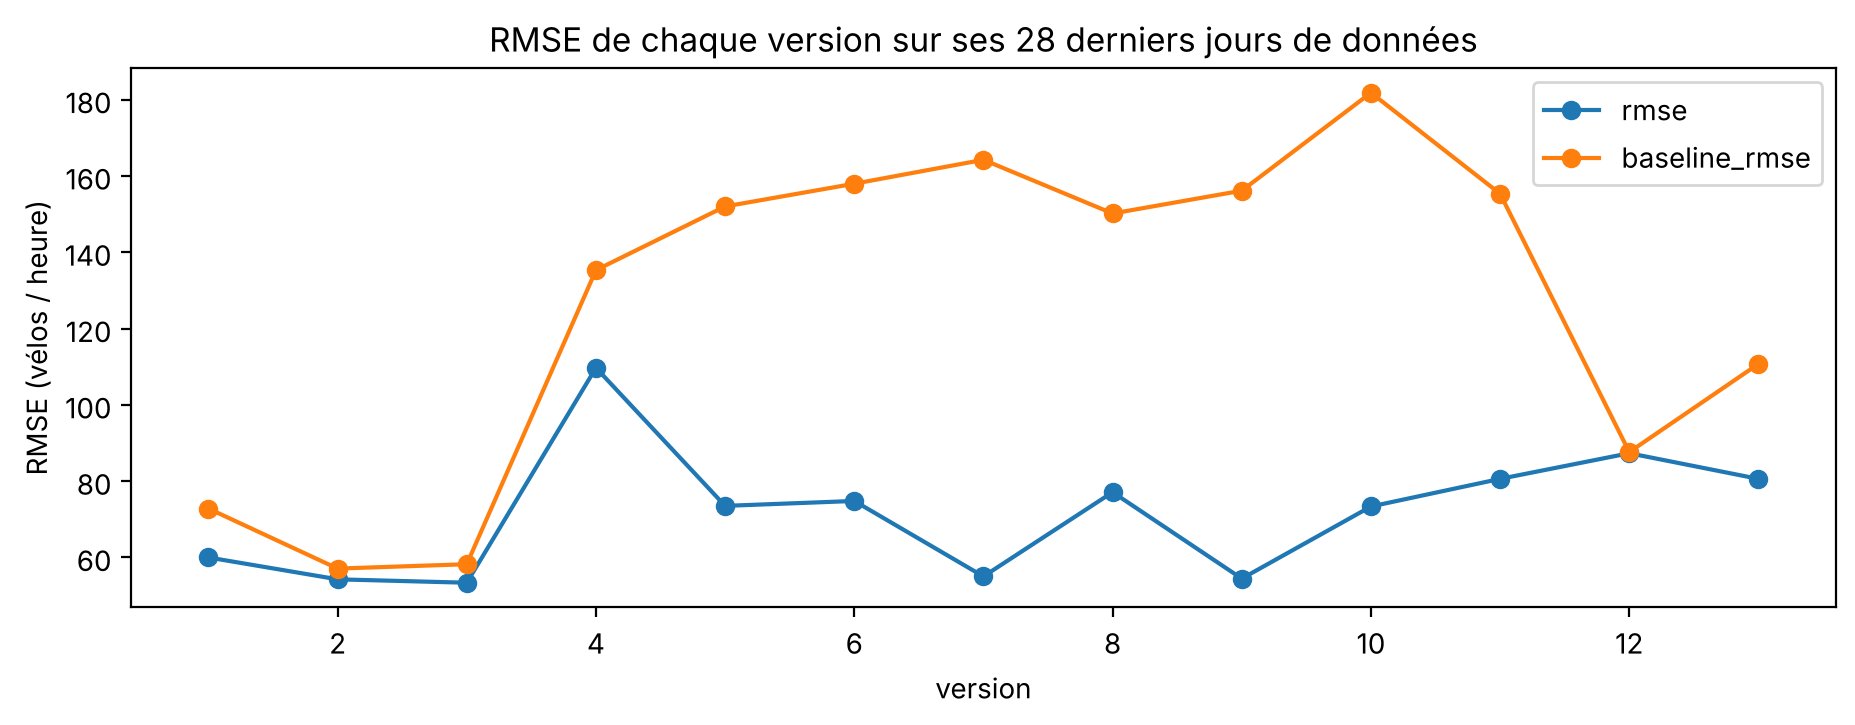

In [14]:
from bikeml.model.registry import get_alias_version, list_versions
versions = pd.DataFrame(list_versions(cfg))
display(versions)

ax = versions.plot(x="version", y=["rmse", "baseline_rmse"], marker="o", figsize=(11, 3.5),
                   title="RMSE de chaque version sur ses 28 derniers jours de données")
ax.set_ylabel("RMSE (vélos / heure)")
plt.show()

**Lecture :**
- Le RMSE varie d'un mois à l'autre parce que **la période d'évaluation change** (on évalue toujours sur les 28 derniers jours disponibles) : les mois de forte demande donnent mécaniquement des erreurs absolues plus grandes. C'est précisément pour cela que la règle de promotion compare challenger et champion **sur la même période**, et non les RMSE de versions différentes entre elles.
- Chaque version bat la référence naïve. L'écart est très net d'avril à octobre (RMSE divisé par 2 à 3), plus modeste en hiver (v1 à v3 : 5 à 18 % de mieux) et quasi nul en novembre (87.3 contre 87.6 : mois de transition, demande en baisse rapide).
- Chaque nouveau lot a produit une version promue : le challenger a vu le mois le plus récent, l'ancien champion non, et la pondération par l'ancienneté donne l'avantage au premier. Pour la dernière version, la **tolérance de 2 %** a joué : le challenger était très légèrement moins bon que le champion sur la période, mais dans la marge admise. Cette tolérance évite de garder indéfiniment un modèle ancien pour un écart non significatif.

In [15]:
sql("SELECT batch, status, model_version, promoted, round(rmse,1) AS rmse, message FROM pipeline_runs ORDER BY started_at")

,batch,status,model_version,promoted,rmse,message
0,0000_initial.csv,SUCCESS,1,1,60.0,premier modèle valide (RMSE 60.0)
1,2012-01.csv,SUCCESS,2,1,54.3,RMSE 54.3 <= champion 64.1 x 1.02
2,2012-02.csv,SUCCESS,3,1,53.4,RMSE 53.4 <= champion 67.9 x 1.02
3,2012-03.csv,SUCCESS,4,1,109.7,RMSE 109.7 <= champion 110.7 x 1.02
4,2012-04.csv,SUCCESS,5,1,73.5,RMSE 73.5 <= champion 107.8 x 1.02
5,2012-05.csv,SUCCESS,6,1,74.8,RMSE 74.8 <= champion 82.8 x 1.02
6,2012-06.csv,SUCCESS,7,1,55.0,RMSE 55.0 <= champion 83.8 x 1.02
7,2012-07.csv,SUCCESS,8,1,77.1,RMSE 77.1 <= champion 86.4 x 1.02
8,2012-08.csv,SUCCESS,9,1,54.5,RMSE 54.5 <= champion 75.7 x 1.02
9,2012-09.csv,SUCCESS,10,1,73.4,RMSE 73.4 <= champion 75.3 x 1.02


### 8.4 Une version moins bonne est-elle bloquée ?
Les règles de mise en service ne servent que si elles bloquent réellement un mauvais modèle. La commande `retrain` relance un entraînement à la demande, avec d'autres hyperparamètres, **en passant par les mêmes règles que le pipeline**. On essaie ici un modèle volontairement sous-entraîné (30 itérations au lieu de 300) :

In [16]:
run("retrain", "--set", "max_iter=30", keep=["bikeml.train", "bikeml.registry", "ALERTE", '"version"'])
print("Champion toujours en service : v" + get_alias_version("champion", cfg))
pd.DataFrame(list_versions(cfg)).tail(2)

{"version": "14", "promoted": false, "reason": "RMSE 85.9 > champion 80.6 x 1.02"}
2026-11-18 10:41:03,598 INFO    bikeml.train - Modèle v14 entraîné : RMSE=85.9 MAE=54.9 R2=0.716 (référence naïve RMSE=110.7)
2026-11-18 10:41:03,747 INFO    bikeml.registry - Version 14 rejetée (RMSE 85.9 > champion 80.6 x 1.02)
2026-11-18 10:41:03,747 WARNING bikeml.alerts - [ALERTE] Version 14 non promue : RMSE 85.9 > champion 80.6 x 1.02
--> code retour : 0
Champion toujours en service : v13


,version,aliases,status,rmse,baseline_rmse,trigger_batch,decision
12,13,champion,champion,80.59,110.72,2012-12.csv,RMSE 80.6 <= champion 80.2 x 1.02
13,14,,rejected,85.91,110.72,reentrainement-manuel,RMSE 85.9 > champion 80.6 x 1.02


La version est bien enregistrée (on garde la trace de toutes les tentatives), marquée `rejected` avec la justification, une alerte est émise, et le champion reste en place.

<a id="9"></a>
## 9. Incident contrôlé n°1 : un lot de données invalide

Scénario : un système amont livre un fichier défectueux. La commande `release-bad` fabrique un lot qui cumule plusieurs défauts réalistes :
- une **colonne manquante** (`windspeed`) ;
- des **valeurs manquantes** sur la température ;
- des **heures impossibles** (27 h) ;
- des **comptages négatifs** ;
- des **lignes en double**.

**Comportement attendu :** le pipeline s'arrête à l'étape de validation, n'entraîne rien, met le lot en quarantaine, écrit un rapport, émet une alerte, et **le champion en service ne change pas**.

In [17]:
from bikeml.model.registry import get_alias_version
champion_avant = get_alias_version("champion", cfg)
print("Champion avant l'incident : v" + champion_avant)

run("release-bad")
code_retour = run("run", keep=["ALERTE", "Lots en échec", "Finished in state Failed"], tail=6)

Champion avant l'incident : v13


data/incoming/corrupted_batch.csv
2026-11-18 10:41:05,253 INFO    bikeml.ingest - Lot invalide déposé : corrupted_batch.csv
--> code retour : 0


2026-11-18 10:41:14,800 INFO    prefect.flow_runs - Finished in state Failed("Flow run encountered an exception: DataValidationError: Lot non conforme -> schema: colonnes manquantes : ['windspeed']; completude: taux max de manquants : 6.25%; unicite: taux de doublons (date, heure) : 7.50%; bornes: valeurs hors bornes : {'hr': 10, 'cnt': 10}; coherence: 10 lignes où casual + registered != cnt")
2026-11-18 10:41:15,570 ERROR   prefect.flow_runs - Encountered exception during execution: RuntimeError("Lots en échec : ['corrupted_batch.csv']")
    raise RuntimeError(f"Lots en échec : {failures}")
RuntimeError: Lots en échec : ['corrupted_batch.csv']
2026-11-18 10:41:15,600 INFO    prefect.flow_runs - Finished in state Failed("Flow run encountered an exception: RuntimeError: Lots en échec : ['corrupted_batch.csv']")
Pipeline en échec : Lots en échec : ['corrupted_batch.csv']
--> code retour : 1


In [18]:
print("Code retour du pipeline :", code_retour, "(différent de 0 : l'échec est visible par un ordonnanceur ou une CI)")
print("Quarantaine :", [p.name for p in (ROOT / "data/quarantine").glob("*.csv")])
print("Lot absent des données acceptées :", not (ROOT / "data/accepted/corrupted_batch.csv").exists())
print("Champion après l'incident : v" + get_alias_version("champion", cfg), "(inchangé)")
print("Nombre de versions dans le registre :", len(list_versions(cfg)), "(aucune nouvelle version)")

rapport = json.loads((ROOT / "reports/validation/corrupted_batch.json").read_text())
display(pd.DataFrame(rapport["checks"]))
display(sql("SELECT ts, level, source, message FROM alerts WHERE source IN ('validation','prefect') ORDER BY id DESC"))

Code retour du pipeline : 1 (différent de 0 : l'échec est visible par un ordonnanceur ou une CI)
Quarantaine : ['corrupted_batch.csv']
Lot absent des données acceptées : True
Champion après l'incident : v13 (inchangé)
Nombre de versions dans le registre : 14 (aucune nouvelle version)


,name,passed,detail
0,schema,False,colonnes manquantes : ['windspeed']
1,volume,True,320 lignes (min 100)
2,completude,False,taux max de manquants : 6.25%
3,unicite,False,"taux de doublons (date, heure) : 7.50%"
4,types,True,ok
5,bornes,False,"valeurs hors bornes : {'hr': 10, 'cnt': 10}"
6,coherence,False,10 lignes où casual + registered != cnt
7,dates,True,0 dates illisibles


,ts,level,source,message
0,2026-11-18T10:41:14.794+00:00,ERROR,prefect,Le flow caped-mandrill a échoué : Flow run encountered an exception: DataValidationError: Lot non conforme...
1,2026-11-18T10:41:13.781+00:00,ERROR,validation,Lot corrupted_batch.csv rejeté et mis en quarantaine. Lot non conforme -> schema: colonnes manquantes : ['...


Tous les défauts injectés ont été détectés, chacun par le contrôle correspondant. Le run apparaît avec le statut `REJECTED` dans la table de suivi et dans le dashboard. Pour réintégrer un lot corrigé, il suffit de redéposer le fichier corrigé dans `data/incoming/`.

<a id="10"></a>
## 10. API de prédiction, persistance et feedbacks

Code : `src/bikeml/api/`. Documentation interactive générée automatiquement sur <http://127.0.0.1:8000/docs>.

| Endpoint | Rôle |
|---|---|
| `GET /health` | état du service (`ok` / `degraded`), version servie, dernière erreur |
| `GET /model` | informations sur la version servie |
| `POST /predict` | prédiction **en ligne** (un créneau) |
| `POST /predict/batch` | prédiction **par lot** (jusqu'à 500 créneaux, configurable) |
| `POST /feedback` | valeur réellement observée pour une prédiction passée (un seul retour par prédiction) |
| `POST /admin/reload` | recharge le champion depuis le registre (appelé par le pipeline après une promotion) ; protégé par jeton (`X-Admin-Token`) si `BIKEML_ADMIN_TOKEN` est défini |
| `GET /metrics` | métriques au format Prometheus |

**Validation des entrées :** les schémas Pydantic imposent les types, les bornes (heure 0-23, température 0-1...) et **refusent les champs inconnus**. Une entrée invalide reçoit une réponse **422** qui détaille champ par champ ce qui ne va pas, sans jamais atteindre le modèle.

**Gestion des erreurs :** 422 entrée invalide, 413 lot trop grand, 404 feedback sur une prédiction inconnue, **409 feedback déjà reçu** pour cette prédiction (un doublon fausserait l'erreur mesurée), 401 jeton d'administration invalide, **503 modèle indisponible** (au lieu d'un plantage), 500 erreur interne capturée proprement. Chaque réponse contient un `request_id` **généré par le serveur** (jamais repris du client : c'est la clé qui relie une prédiction à son feedback, elle doit être unique), aussi renvoyé dans l'en-tête `X-Request-ID`, ainsi que la version du modèle (`X-Model-Version`).

**Identification de la version :** chaque réponse indique `model_version`.

**Persistance (`data/ops.db`) :**
- `requests` : chaque appel (horodatage, endpoint, code retour, **durée**, version, erreur éventuelle) ;
- `predictions` : chaque prédiction avec **ses entrées complètes** et la version qui l'a produite ;
- `feedback` : la valeur réelle observée, rattachée à la prédiction et donc à la version.

On démarre l'API en arrière-plan :

In [19]:
API = "http://127.0.0.1:8000"
(ROOT / "data/logs").mkdir(parents=True, exist_ok=True)


def start_api(port=8000, extra_env=None, log_name="api.log"):
    env = {**os.environ, **(extra_env or {})}
    log = open(ROOT / "data/logs" / log_name, "w")
    proc = subprocess.Popen([PY, "-m", "bikeml", "api", "--port", str(port)], cwd=ROOT, env=env,
                            stdout=log, stderr=subprocess.STDOUT)
    for _ in range(120):
        try:
            return proc, httpx.get(f"http://127.0.0.1:{port}/health", timeout=2).json()
        except Exception:
            time.sleep(1)
    raise RuntimeError("l'API ne répond pas")


api_proc, health = start_api()
print(health)

if IN_COLAB:
    # Colab : ouvre la documentation interactive de l'API dans un nouvel onglet
    from google.colab import output
    output.serve_kernel_port_as_window(8000, path="/docs", anchor_text="Ouvrir la documentation de l'API (/docs)")

{'status': 'ok', 'model_version': '13', 'loaded_at': '2026-11-18T10:41:20+00:00', 'last_error': None}


In [20]:
exemple = {"season": 3, "mnth": 7, "hr": 17, "holiday": 0, "weekday": 3, "workingday": 1,
           "weathersit": 1, "temp": 0.72, "atemp": 0.66, "hum": 0.45, "windspeed": 0.19}

print("--- Prédiction en ligne : un mercredi de juillet à 17 h, beau temps")
r = httpx.post(f"{API}/predict", json=exemple)
print(r.status_code, r.json(), "| en-tête X-Model-Version :", r.headers["X-Model-Version"])

print("\n--- Prédiction par lot : la même journée heure par heure")
journee = [{**exemple, "hr": h} for h in range(24)]
r = httpx.post(f"{API}/predict/batch", json={"items": journee})
print(r.status_code, "version", r.json()["model_version"], "->", r.json()["predictions"])

print("\n--- Entrée invalide : heure = 30, température = 'chaud', champ inconnu")
r = httpx.post(f"{API}/predict", json={**exemple, "hr": 30, "temp": "chaud", "pluie": 1})
print(r.status_code, json.dumps(r.json(), ensure_ascii=False, indent=1))

print("\n--- Lot trop grand")
r = httpx.post(f"{API}/predict/batch", json={"items": [exemple] * 501})
print(r.status_code, r.json()["detail"])

--- Prédiction en ligne : un mercredi de juillet à 17 h, beau temps
200 {'request_id': 'c795afc3d6c44c7eba28d77c5f3dc9d1', 'prediction': 848.02, 'model_version': '13', 'latency_ms': 13.13} | en-tête X-Model-Version : 13

--- Prédiction par lot : la même journée heure par heure
200 version 13 -> [63.76, 20.54, 11.32, 5.49, 7.54, 37.38, 157.4, 451.74, 720.43, 363.09, 215.97, 244.89, 311.7, 311.17, 293.99, 324.84, 481.37, 848.02, 825.28, 573.44, 435.55, 323.01, 249.16, 154.32]

--- Entrée invalide : heure = 30, température = 'chaud', champ inconnu
422 {
 "detail": "entrée invalide",
 "errors": [
  {
   "champ": "hr",
   "erreur": "Input should be less than or equal to 23"
  },
  {
   "champ": "temp",
   "erreur": "Input should be a valid number, unable to parse string as a number"
  },
  {
   "champ": "pluie",
   "erreur": "Extra inputs are not permitted"
  }
 ],
 "request_id": "a1b110362e2141b5941b2867767af433"
}

--- Lot trop grand
413 lot trop grand (max 500)


### Boucle de feedback
En production, la valeur réelle est connue une heure plus tard. Pour la simuler, on prend 300 créneaux de décembre 2012, on demande les prédictions, puis on renvoie pour chacune la valeur réellement observée via `/feedback`. L'API rattache chaque retour à la prédiction d'origine et à la version du modèle : on peut alors **mesurer l'erreur réelle en production, par version**, indépendamment de l'évaluation faite à l'entraînement.

In [21]:
from bikeml.api.schemas import BikeFeatures

champs_api = list(BikeFeatures.model_fields)      # le contrat d'entrée de l'API
reel = pd.read_csv("data/accepted/2012-12.csv").sample(300, random_state=0)

envoyes = 0
for start in range(0, len(reel), 50):
    chunk = reel.iloc[start:start + 50]
    reponse = httpx.post(f"{API}/predict/batch", json={"items": chunk[champs_api].to_dict("records")})
    reponse.raise_for_status()
    rep = reponse.json()
    for i, actual in enumerate(chunk["cnt"]):
        httpx.post(f"{API}/feedback", json={"request_id": rep["request_id"], "item_index": i,
                                            "actual_cnt": float(actual)})
        envoyes += 1
print(f"{envoyes} feedbacks envoyés")
doublon = httpx.post(f"{API}/feedback", json={"request_id": rep["request_id"], "item_index": 0, "actual_cnt": 1.0})
print("Second feedback pour la même prédiction ->", doublon.status_code, doublon.json()["detail"])

fb = sql("SELECT model_version, COUNT(*) AS n, AVG(ABS(actual - prediction)) AS mae, "
         "SQRT(AVG((actual - prediction)*(actual - prediction))) AS rmse FROM feedback GROUP BY model_version")
fb.round(1)

300 feedbacks envoyés
Second feedback pour la même prédiction -> 409 feedback déjà enregistré pour cette prédiction


,model_version,n,mae,rmse
0,13,300,40.6,65.9


In [22]:
print("Traces enregistrées par l'API :")
display(sql("SELECT endpoint, status_code, COUNT(*) AS appels, ROUND(AVG(latency_ms),1) AS latence_moy_ms, "
            "MAX(model_version) AS version FROM requests GROUP BY endpoint, status_code ORDER BY appels DESC"))
display(sql("SELECT request_id, item_index, features, prediction, model_version FROM predictions LIMIT 3"))
print("Extrait de /metrics (format Prometheus) :")
print("\n".join(l for l in httpx.get(f"{API}/metrics").text.splitlines() if l.startswith("bikeml_requests_total")))

Traces enregistrées par l'API :


,endpoint,status_code,appels,latence_moy_ms,version
0,/feedback,200,300,4.0,13
1,/predict/batch,200,7,13.2,13
2,/feedback,409,1,1.5,13
3,/health,200,1,1.6,13
4,/predict,200,1,15.2,13
5,/predict,422,1,0.7,13
6,/predict/batch,413,1,4.3,13


,request_id,item_index,features,prediction,model_version
0,c795afc3d6c44c7eba28d77c5f3dc9d1,0,"{""season"": 3, ""mnth"": 7, ""hr"": 17, ""holiday"": 0, ""weekday"": 3, ""workingday"": 1, ""weathersit"": 1, ""temp"": 0...",848.02,13
1,7be3534d21d24017b836cf219a5c3340,0,"{""season"": 3, ""mnth"": 7, ""hr"": 0, ""holiday"": 0, ""weekday"": 3, ""workingday"": 1, ""weathersit"": 1, ""temp"": 0....",63.76,13
2,7be3534d21d24017b836cf219a5c3340,1,"{""season"": 3, ""mnth"": 7, ""hr"": 1, ""holiday"": 0, ""weekday"": 3, ""workingday"": 1, ""weathersit"": 1, ""temp"": 0....",20.54,13


Extrait de /metrics (format Prometheus) :
bikeml_requests_total{endpoint="/health",status="200"} 1.0
bikeml_requests_total{endpoint="/predict",status="200"} 1.0
bikeml_requests_total{endpoint="/predict/batch",status="200"} 7.0
bikeml_requests_total{endpoint="/predict",status="422"} 1.0
bikeml_requests_total{endpoint="/predict/batch",status="413"} 1.0
bikeml_requests_total{endpoint="/feedback",status="200"} 300.0
bikeml_requests_total{endpoint="/feedback",status="409"} 1.0


<a id="11"></a>
## 11. Incident contrôlé n°2 : dépendance indisponible

Scénario : le **registre de modèles** (ici un serveur MLflow) est en panne au moment où une instance de l'API démarre. Sans précaution, l'API planterait au démarrage, ou bloquerait plusieurs minutes en réessayant.

**Comportement prévu (`api/model_service.py`) :**
- l'API démarre quand même, en état **`degraded`**, après quelques secondes seulement (délai et nombre de tentatives HTTP bornés) ;
- `/health` expose la cause exacte de la panne ;
- `/predict` répond **503 « modèle indisponible »**, un code explicite que le client peut gérer (réessayer plus tard) ;
- une **alerte** est enregistrée et chaque appel en échec est tracé ;
- quand la dépendance revient, un simple `POST /admin/reload` remet le service en état nominal, **sans redémarrage** ;
- et si un rechargement échoue alors qu'un modèle était déjà chargé, **l'ancien modèle reste servi** (vérifié par un test automatique).

On lance une seconde instance de l'API (port 8001) configurée pour utiliser un serveur MLflow sur le port 5001, qui n'est pas démarré :

In [23]:
REGISTRE = "http://127.0.0.1:5001"
api2_proc, health2 = start_api(8001, {"MLFLOW_TRACKING_URI": REGISTRE}, "api_incident.log")
print("Santé :", json.dumps(health2, ensure_ascii=False, indent=1)[:400])

r = httpx.post("http://127.0.0.1:8001/predict", json=exemple)
print("\n/predict ->", r.status_code, r.json()["detail"][:120], "...")
display(sql("SELECT ts, level, source, substr(message, 1, 110) AS message FROM alerts WHERE source='api' ORDER BY id DESC LIMIT 1"))

Santé : {
 "status": "degraded",
 "model_version": null,
 "loaded_at": null,
 "last_error": "MlflowException: API request to http://127.0.0.1:5001/api/2.0/mlflow/experiments/get-by-name failed with exception HTTPConnectionPool(host='127.0.0.1', port=5001): Max retries exceeded with url: /api/2.0/mlflow/experiments/get-by-name?experiment_name=velo-demand (Caused by NewConnectionError(\"HTTPCo"
}

/predict -> 503 modèle indisponible : MlflowException: API request to http://127.0.0.1:5001/api/2.0/mlflow/experiments/get-by-name faile ...


,ts,level,source,message
0,2026-11-18T10:41:29.373+00:00,ERROR,api,Démarrage dégradé : MlflowException: API request to http://127.0.0.1:5001/api/2.0/mlflow/experiments/get-b...


On rétablit la dépendance en démarrant le serveur MLflow (adossé au même registre local), puis on demande à l'API de recharger le modèle :

In [24]:
mlflow_server = subprocess.Popen(
    [PY, "-m", "mlflow", "server", "--backend-store-uri", "sqlite:///mlflow.db", "--host", "127.0.0.1", "--port", "5001"],
    cwd=ROOT, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        httpx.get(f"{REGISTRE}/health", timeout=2)
        break
    except Exception:
        time.sleep(1)

print("Rechargement :", httpx.post("http://127.0.0.1:8001/admin/reload", timeout=60).json())
print("Santé        :", httpx.get("http://127.0.0.1:8001/health").json())
print("Prédiction   :", httpx.post("http://127.0.0.1:8001/predict", json=exemple).json())

for p in (api2_proc, mlflow_server):
    p.terminate()
    p.wait()

Rechargement : {'previous_version': None, 'model_version': '13'}
Santé        : {'status': 'ok', 'model_version': '13', 'loaded_at': '2026-11-18T10:41:39+00:00', 'last_error': None}
Prédiction   : {'request_id': '08b8874e1fb942b19c66b36a328be319', 'prediction': 848.02, 'model_version': '13', 'latency_ms': 16.41}


<a id="12"></a>
## 12. Retour à une version précédente (rollback)

Scénario : après une mise en service, les feedbacks montrent une dégradation (ou un bug est découvert). Il faut revenir **immédiatement** à la version précédente, sans réentraîner.

`python -m bikeml rollback` :
1. déplace l'alias `@champion` sur la version portant l'alias `@previous` (ou sur une version précise avec `--version N`) ;
2. marque la version retirée `rolled_back` et **ajoute** la bascule à la justification d'origine (tag `decision`) ;
3. déplace `@previous` sur l'ancien champion antérieur à la cible (statut `archived`), **jamais sur la version qu'on vient de retirer** : un second `rollback` ne peut donc pas remettre en service le modèle défaillant ;
4. notifie l'API, qui recharge le modèle **à chaud**.

Les prédictions servies ensuite portent le nouveau numéro de version : la traçabilité est conservée.

In [25]:
champion = get_alias_version("champion", cfg)
precedent = get_alias_version("previous", cfg)
print(f"Avant  : champion = v{champion}, previous = v{precedent}")
print("API    :", httpx.get(f"{API}/health").json()["model_version"])

run("rollback", keep=["champion", "Rollback", "API"])
print("API    :", httpx.get(f"{API}/health").json()["model_version"])
print("Prédiction servie par :", httpx.post(f"{API}/predict", json=exemple).json()["model_version"])

Avant  : champion = v13, previous = v12
API    : 13


champion -> v12
2026-11-18 10:41:44,627 WARNING bikeml.registry - Rollback : champion v13 -> v12 (previous -> v11)
2026-11-18 10:41:44,717 INFO    bikeml.steps - API notifiée : rechargement du champion.
--> code retour : 0
API    : 12
Prédiction servie par : 12


Retour à l'état nominal : on remet en service la version qui était champion avant l'exercice.

In [26]:
run("rollback", "--version", champion, keep=["champion", "API"])
print("API :", httpx.get(f"{API}/health").json()["model_version"])
display(pd.DataFrame(list_versions(cfg)).tail(4))

api_proc.terminate()
api_proc.wait()
print("API arrêtée (libère le CPU pour les tests de charge).")

champion -> v13
2026-11-18 10:41:48,274 WARNING bikeml.registry - Rollback : champion v12 -> v13 (previous -> v11)
2026-11-18 10:41:48,391 INFO    bikeml.steps - API notifiée : rechargement du champion.
--> code retour : 0
API : 13


,version,aliases,status,rmse,baseline_rmse,trigger_batch,decision
10,11,previous,archived,80.59,155.31,2012-10.csv,RMSE 80.6 <= champion 94.3 x 1.02
11,12,,rolled_back,87.31,87.61,2012-11.csv,RMSE 87.3 <= champion 101.1 x 1.02 | rollback depuis v13
12,13,champion,champion,80.59,110.72,2012-12.csv,RMSE 80.6 <= champion 80.2 x 1.02 | rollback depuis v12
13,14,,rejected,85.91,110.72,reentrainement-manuel,RMSE 85.9 > champion 80.6 x 1.02


API arrêtée (libère le CPU pour les tests de charge).


<a id="13"></a>
## 13. Tests de charge et dimensionnement

### Protocole
Script : `scripts/run_load_tests.py`, scénario : `load_tests/locustfile.py`.

**Profil d'usage simulé** (pondérations Locust) : 10 prédictions unitaires pour 2 prédictions par lot de 24 créneaux, 1 feedback et 1 contrôle de santé. Chaque utilisateur virtuel attend 50 à 200 ms entre deux requêtes, ce qui correspond à une charge soutenue. Les entrées sont tirées aléatoirement dans les domaines valides.

**Configurations comparées :** l'API avec **1 puis 2 workers** uvicorn (processus parallèles). Chaque worker est limité à un thread de calcul (`OMP_NUM_THREADS=1`, fixé par `python -m bikeml api`) : sans cette limite, chaque prédiction du gradient boosting lançait un pool de threads sur tous les cœurs et les requêtes simultanées se disputaient le CPU (mesure préalable sur 1 worker / 10 utilisateurs : CPU 138 % → 76 %, p50 120 → 57 ms).
**Niveaux de charge :** **10, 25 et 50 utilisateurs simultanés**, 20 secondes chacun (montée en charge de 20 utilisateurs/s).

**Mesures collectées :**
- côté client (Locust) : nombre de requêtes, **débit** (req/s), latences **p50 / p95 / p99**, **taux d'erreur** ;
- côté serveur (psutil, échantillonné chaque seconde sur l'API et tous ses workers) : **CPU** moyen et maximal, **mémoire** maximale.

**Objectif de service (SLO)**, défini dans la configuration : **p95 ≤ 200 ms et taux d'erreur ≤ 1 %**.
La recommandation retient, pour chaque niveau de charge, **la plus petite configuration qui respecte le SLO**.

**Isolation :** l'API testée écrit ses traces dans une base séparée (`data/ops_loadtest.db`) : le trafic synthétique et ses feedbacks aléatoires ne faussent pas la supervision du service réel (onglets *Service* et *Qualité*).

*Remarque de méthode :* le générateur de charge tourne sur la même machine que l'API et lui prend du CPU. Les chiffres sont donc **pessimistes** ; ils restent valables pour comparer les configurations entre elles.

La cellule prend environ 3 minutes.

In [27]:
proc = subprocess.run([PY, "scripts/run_load_tests.py"], cwd=ROOT, capture_output=True, text=True)
print(proc.stdout[-300:] if proc.returncode == 0 else proc.stderr[-2000:])

 360 | 137.9% | 810 Mo |
| 50 | aucune config. testée ne tient le SLO (meilleure : 2 worker(s), p95 860 ms) | 91.9 | 860 | 141.1% | 823 Mo |

CPU en % d'un cœur (200 % = 2 cœurs pleinement utilisés). Le générateur de charge tourne sur la même machine que l'API : les chiffres sont donc pessimistes.




Machine de mesure : 4 vCPU, 15.7 Go de RAM


,workers,users,requests,failures,error_rate,rps,p50_ms,p95_ms,p99_ms,cpu_mean_pct,cpu_max_pct,ram_max_mb
0,1,10,1009,0,0.0,53.1,50.0,160.0,210.0,77.4,90.9,383.8
1,1,25,1056,0,0.0,56.3,330.0,520.0,600.0,98.0,107.8,390.8
2,1,50,1040,0,0.0,55.6,750.0,1000.0,1200.0,97.7,106.8,398.3
3,2,10,1215,0,0.0,63.9,23.0,71.0,120.0,77.9,89.8,802.9
4,2,25,1779,0,0.0,93.6,110.0,360.0,530.0,137.9,157.7,810.5
5,2,50,1802,0,0.0,91.9,390.0,860.0,1100.0,141.1,159.7,823.0


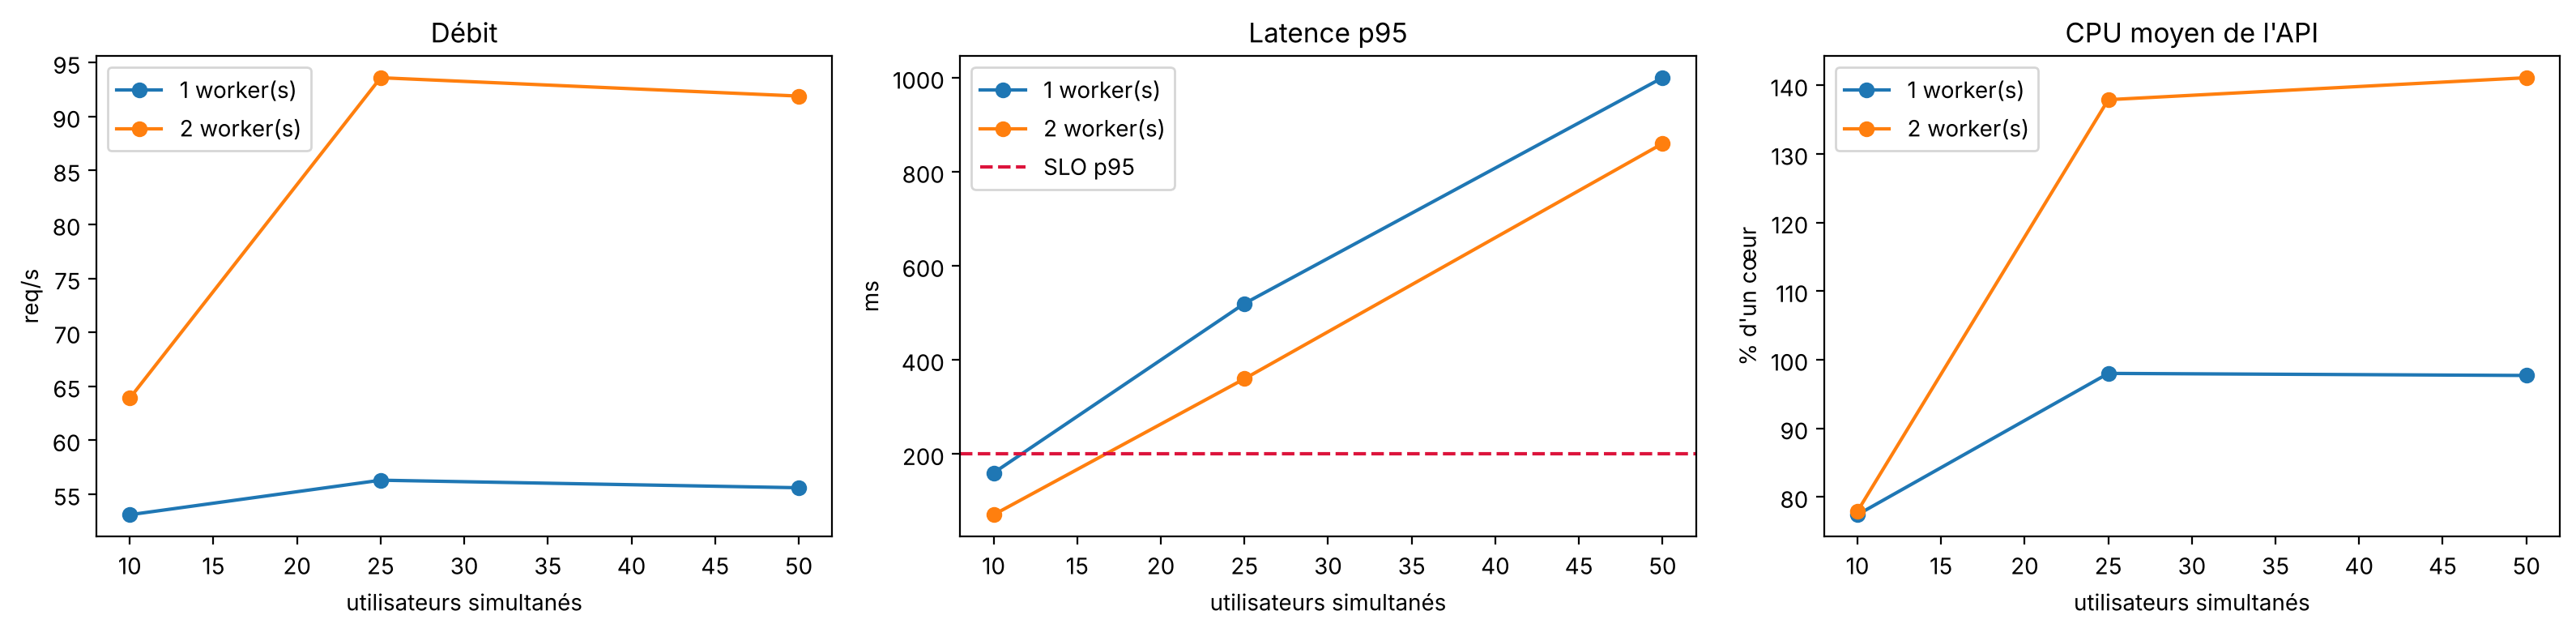

In [28]:
import psutil
print(f"Machine de mesure : {psutil.cpu_count()} vCPU, {psutil.virtual_memory().total / 2**30:.1f} Go de RAM")
res = pd.read_csv("reports/load_tests/summary.csv")
display(res)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for w, g in res.groupby("workers"):
    axes[0].plot(g.users, g.rps, marker="o", label=f"{w} worker(s)")
    axes[1].plot(g.users, g.p95_ms, marker="o", label=f"{w} worker(s)")
    axes[2].plot(g.users, g.cpu_mean_pct, marker="o", label=f"{w} worker(s)")
axes[1].axhline(cfg.load_test["slo_p95_ms"], color="crimson", ls="--", label="SLO p95")
for ax, t, y in zip(axes, ["Débit", "Latence p95", "CPU moyen de l'API"], ["req/s", "ms", "% d'un cœur"]):
    ax.set(title=t, xlabel="utilisateurs simultanés", ylabel=y)
    ax.legend()
plt.tight_layout()
plt.show()

In [29]:
from IPython.display import Markdown
display(Markdown((ROOT / "reports/load_tests/recommendation.md").read_text()))

w1 = res[res.workers == 1]
w2 = res[res.workers == 2]
cap1, cap2 = w1.rps.max(), w2.rps.max()
print(f"Débit maximal observé : {cap1:.0f} req/s avec 1 worker, {cap2:.0f} req/s avec 2 workers "
      f"(x{cap2 / cap1:.2f}).")
print(f"Mémoire : ~{w1.ram_max_mb.max():.0f} Mo pour 1 worker, ~{w2.ram_max_mb.max():.0f} Mo pour 2 workers "
      f"(~{w2.ram_max_mb.max() - w1.ram_max_mb.max():.0f} Mo par worker supplémentaire).")

# Recommandation de dimensionnement

SLO retenu : p95 <= 200 ms et taux d'erreur <= 1%.

| Charge (utilisateurs) | Config. recommandée | Débit (req/s) | p95 (ms) | CPU moyen | RAM max |
|---|---|---|---|---|---|
| 10 | 1 worker(s), 1 vCPU | 53.1 | 160 | 77.4% | 384 Mo |
| 25 | aucune config. testée ne tient le SLO (meilleure : 2 worker(s), p95 360 ms) | 93.6 | 360 | 137.9% | 810 Mo |
| 50 | aucune config. testée ne tient le SLO (meilleure : 2 worker(s), p95 860 ms) | 91.9 | 860 | 141.1% | 823 Mo |

CPU en % d'un cœur (200 % = 2 cœurs pleinement utilisés). Le générateur de charge tourne sur la même machine que l'API : les chiffres sont donc pessimistes.


Débit maximal observé : 56 req/s avec 1 worker, 94 req/s avec 2 workers (x1.66).
Mémoire : ~398 Mo pour 1 worker, ~823 Mo pour 2 workers (~425 Mo par worker supplémentaire).


### Interprétation
*Mesures réalisées sur une machine de 4 vCPU (conteneur cloud) où tournent à la fois l'API et Locust. Une campagne précédente sur une machine de 2 vCPU plus rapide par cœur (type Colab) donnait environ deux fois plus de débit : les chiffres absolus dépendent fortement de la machine, d'où la nécessité de refaire la campagne sur la machine cible.*

- **Le service est limité par le CPU**, pas par la mémoire : avec 1 worker, le CPU plafonne vers 100 % d'un cœur dès 25 utilisateurs et le débit cesse d'augmenter (≈ 56 req/s) ; la mémoire reste stable (~390 Mo par worker, car chaque worker charge son propre modèle et ses bibliothèques).
- **Passer de 1 à 2 workers multiplie le débit maximal par 1,66** (56 → 94 req/s) et divise par deux la p95 à 10 utilisateurs (160 → 71 ms). Le gain est inférieur à x2 car le générateur de charge et l'écriture des traces SQLite partagent les mêmes cœurs.
- **La latence explose avant que des erreurs n'apparaissent** (0 erreur sur toute la campagne) : les requêtes s'accumulent dans la file d'attente, signe classique de saturation CPU. La réponse est d'ajouter des workers *et des cœurs*, ou des instances derrière un répartiteur de charge.

### Recommandation chiffrée
**Demande à servir.** Un utilisateur virtuel attend en moyenne 125 ms entre deux requêtes ; quand le service répond vite, il émet donc ≈ 6,4 req/s (vérifié : 10 utilisateurs → 64 req/s avec 2 workers). Soit ≈ 64 req/s pour 10 utilisateurs, ≈ 160 req/s pour 25 et ≈ 320 req/s pour 50.

**Capacité mesurée.** Sous le SLO, un worker (1 vCPU) sert ≈ 50 req/s. Avec une **marge de 30 %**, on compte **≈ 35 req/s par worker**, d'où *nombre de workers = débit cible ÷ 35* (1 worker = 1 vCPU, ~400 Mo).

| Charge | Débit à servir | Recommandation | Justification |
|---|---|---|---|
| ≈ 10 utilisateurs | ≈ 64 req/s | **2 workers, 2 vCPU, 1 Go** | p95 mesurée 71 ms. 1 worker / 1 vCPU / 512 Mo tient le SLO de justesse (p95 160 ms) mais sature déjà (53 req/s servis) : aucune marge |
| ≈ 25 utilisateurs | ≈ 160 req/s | **≈ 5 workers / 5 vCPU, ~2 Go**, répartis sur 2 instances | aucune configuration testée ne tient le SLO (meilleure : 2 workers, p95 360 ms) ; estimation par la règle ci-dessus |
| ≈ 50 utilisateurs | ≈ 320 req/s | **≈ 9-10 workers, soit 3 instances de 3-4 vCPU, ~4 Go** | idem (2 workers : p95 860 ms) |

Ces deux dernières lignes sont des **extrapolations** à valider par une campagne sur l'infrastructure cible (`make load-test` avec `--workers 1 2 4`).

**Pistes d'optimisation identifiées par les mesures :** 
- *déjà appliquée :* un seul thread de calcul par worker (`OMP_NUM_THREADS=1`) : mesure dédiée à 1 worker / 10 utilisateurs : CPU 138 % → 76 %, p50 120 → 57 ms ;
- l'écriture synchrone des traces dans SQLite à chaque requête et le surcoût de pandas pour une prédiction unitaire pèsent sur la latence : une écriture asynchrone par paquets et une conversion directe en tableau NumPy réduiraient encore le coût par requête.


<a id="14"></a>
## 14. Supervision : le dashboard

Lancement : `streamlit run dashboard/app.py`, puis <http://localhost:8501>. Le dashboard lit la base `data/ops.db`, le registre MLflow et les rapports de charge ; il se rafraîchit à la demande. Il comporte cinq onglets :

| Onglet | Contenu | Question à laquelle il répond |
|---|---|---|
| **Traitements** | exécutions du pipeline (statut, lot, étape, version, décision), compteurs succès / rejets / échecs, journal des alertes | « Les données arrivent-elles et sont-elles bien traitées ? » |
| **Modèles** | version en service, historique des versions, RMSE vs référence, décisions | « Quel modèle est servi et pourquoi ? » |
| **Service** | trafic par minute, latences p50/p95, taux d'erreur, codes retour par endpoint, dernières erreurs | « L'API est-elle disponible et rapide ? » |
| **Qualité** | erreur réelle (MAE, RMSE) mesurée grâce aux feedbacks, par version | « Le modèle reste-t-il bon en production ? » |
| **Charge** | résultats de la dernière campagne et recommandation | « Le dimensionnement est-il suffisant ? » |

On lance le dashboard en arrière-plan. Sur Colab, un lien permet de l'ouvrir dans un nouvel onglet ; en local, il est disponible sur <http://localhost:8501>.

In [30]:
dashboard = subprocess.Popen(
    [PY, "-m", "streamlit", "run", "dashboard/app.py", "--server.headless", "true", "--server.port", "8501",
     "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"],
    cwd=ROOT, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        httpx.get("http://127.0.0.1:8501/_stcore/health", timeout=2)
        break
    except Exception:
        time.sleep(1)

if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(8501, anchor_text="Ouvrir le dashboard de supervision")
else:
    print("Dashboard disponible sur http://localhost:8501")

Dashboard disponible sur http://localhost:8501


Captures du dashboard (onglets *Traitements*, *Modèles*, *Service* et *Qualité*), prises sur l'état produit par cette exécution :

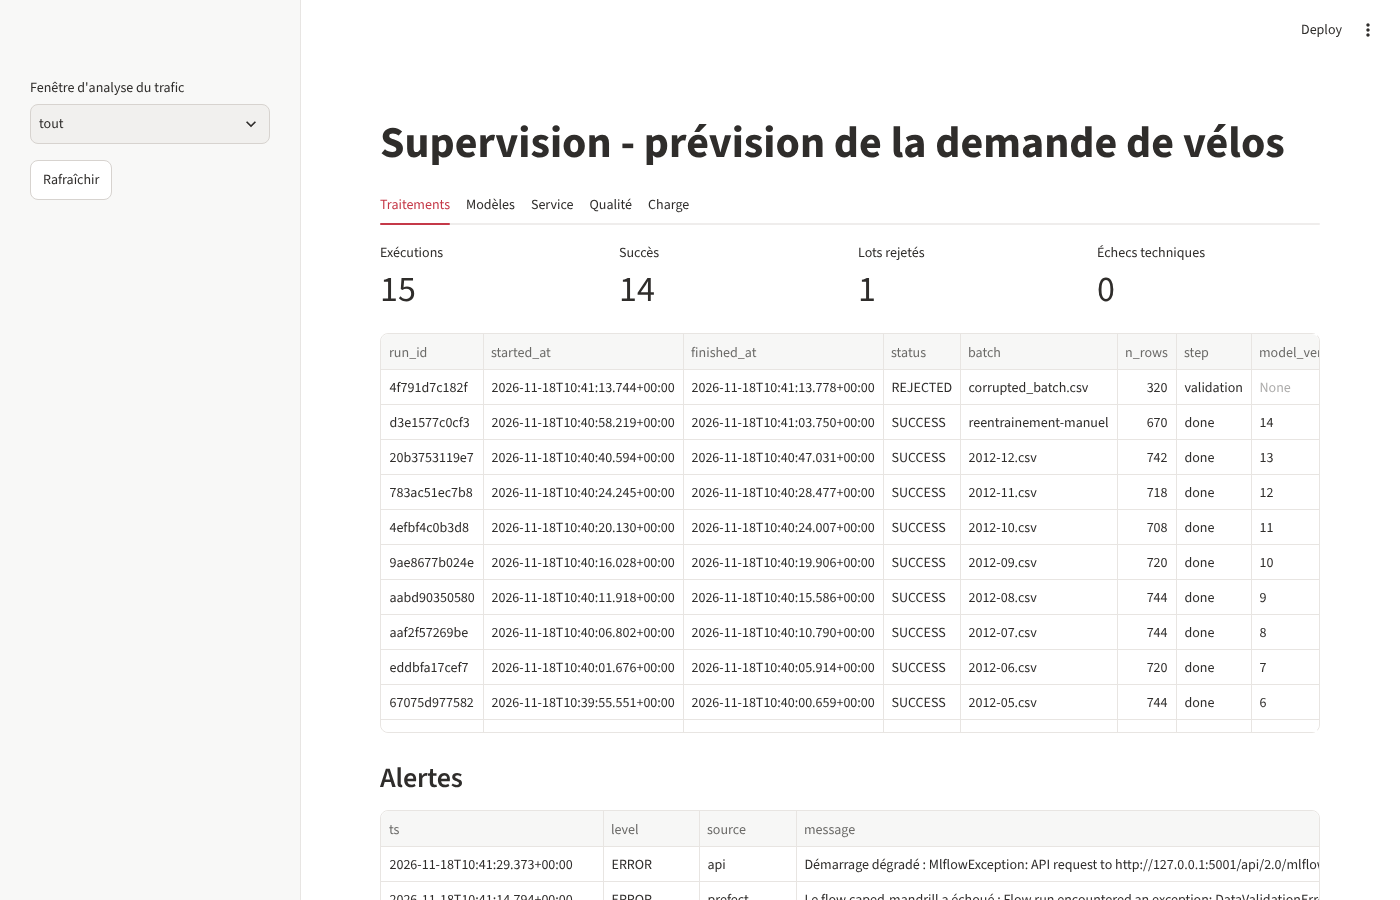

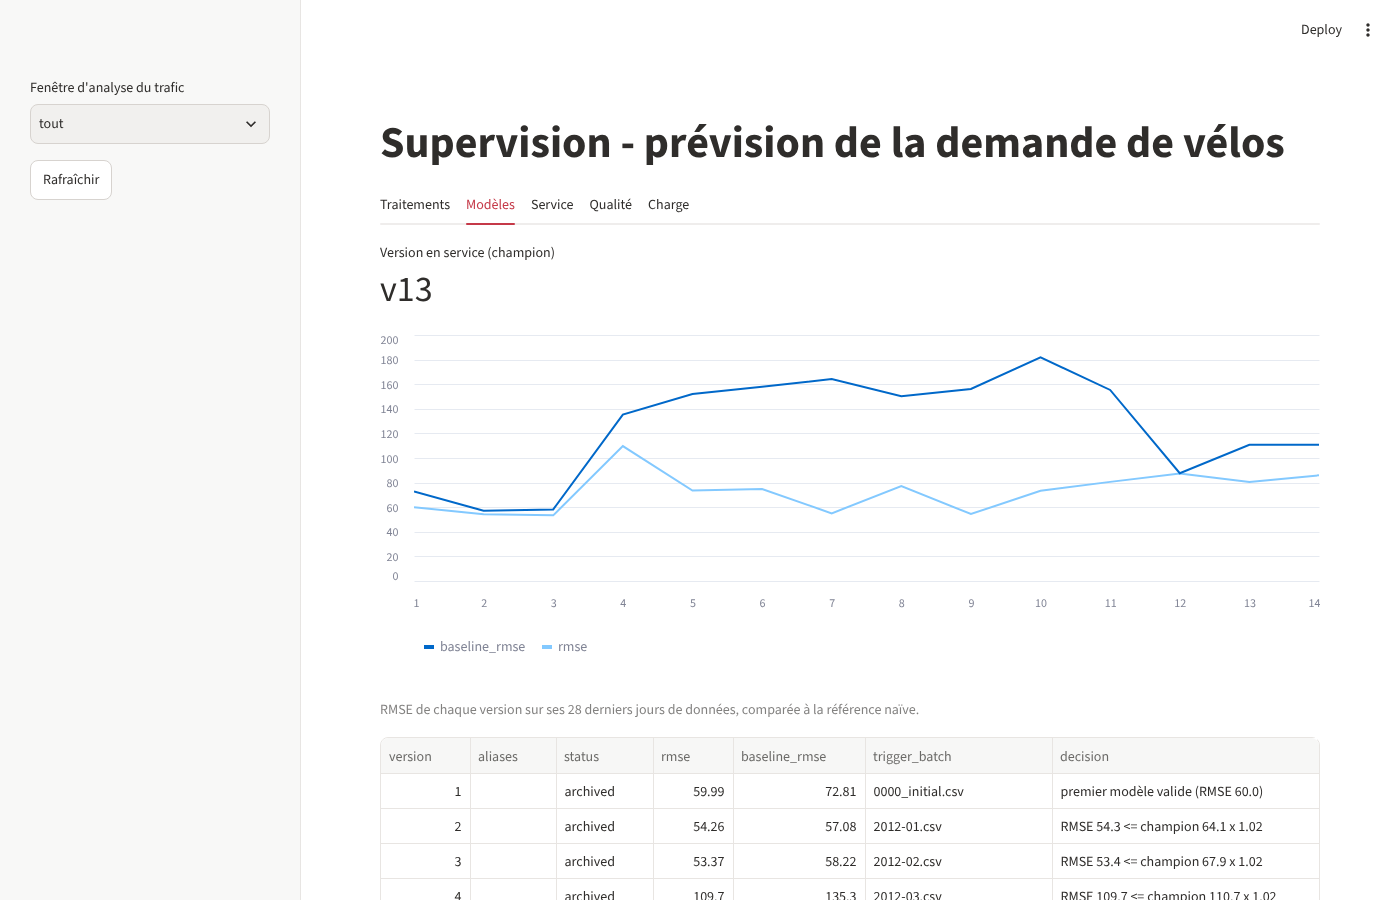

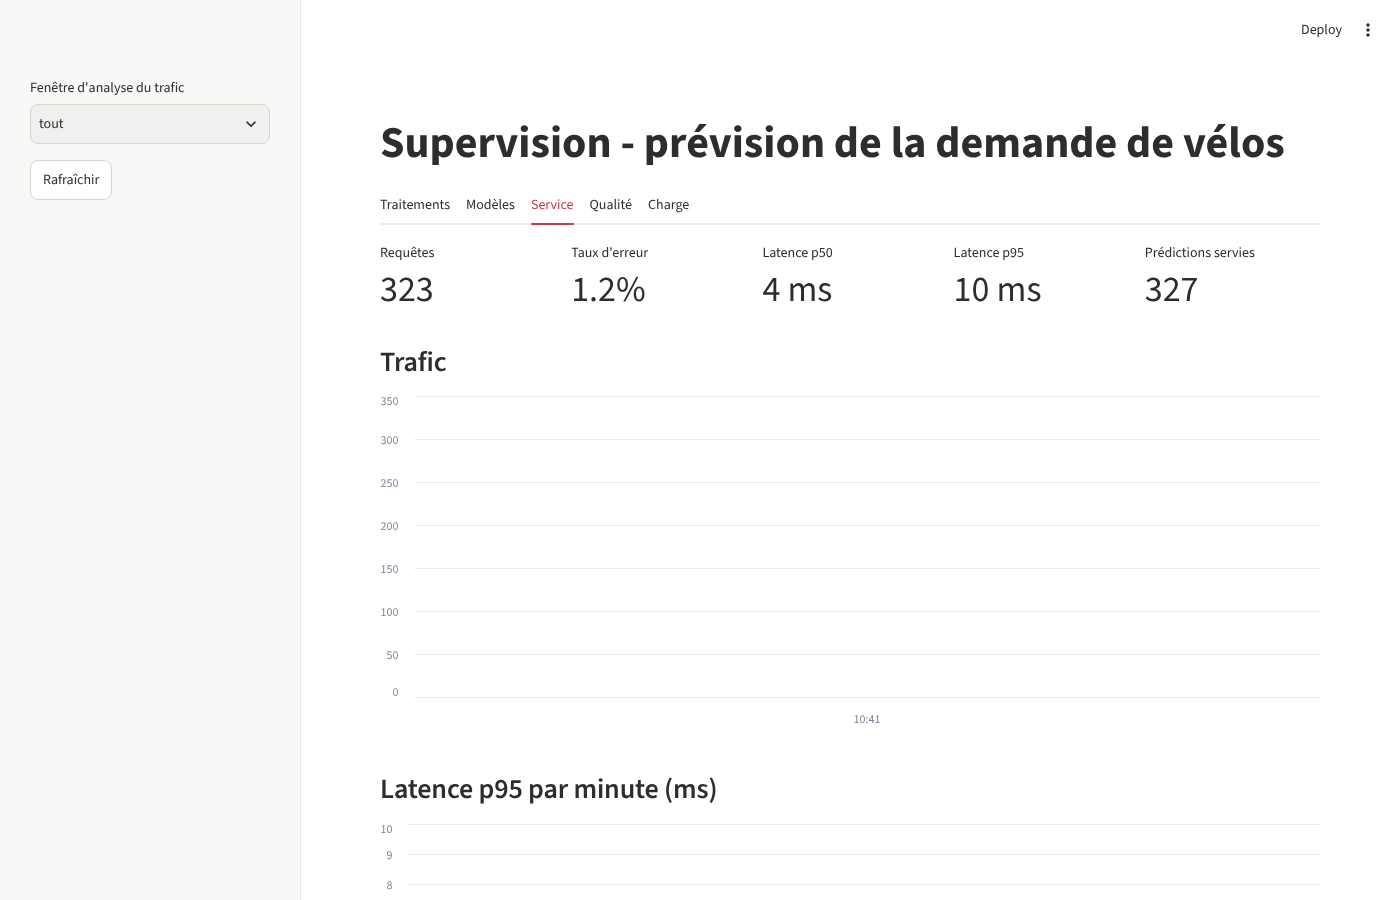

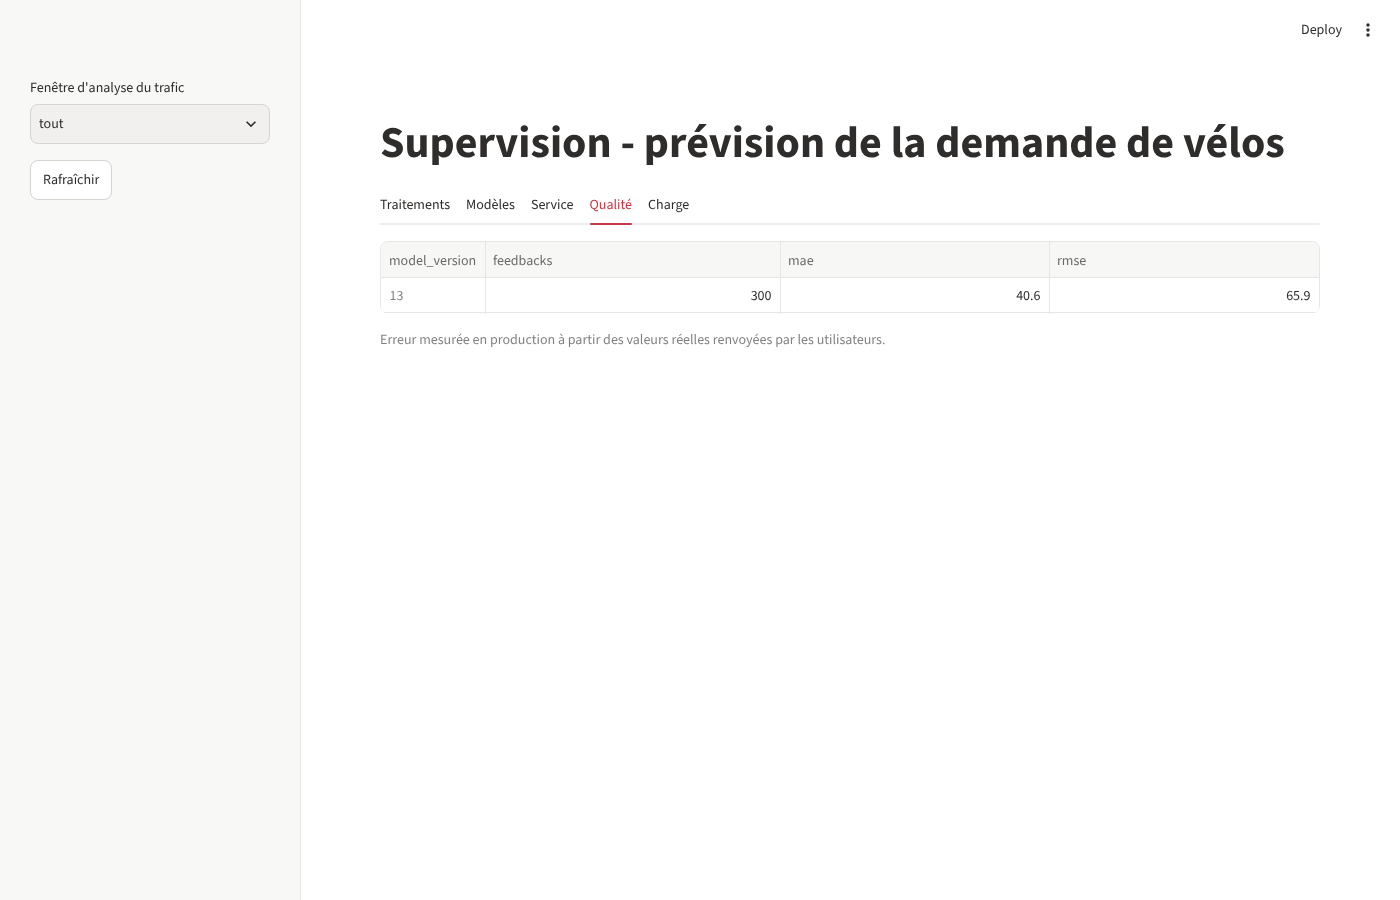

In [31]:
from IPython.display import Image, display
for nom in ["dashboard_traitements", "dashboard_modeles", "dashboard_service", "dashboard_qualite"]:
    display(Image(filename=str(ROOT / "docs" / f"{nom}.png"), width=1000))

Les mêmes indicateurs, calculés directement en SQL :

In [32]:
runs = sql("SELECT status, COUNT(*) AS n FROM pipeline_runs GROUP BY status")
req = sql("SELECT status_code, latency_ms FROM requests")
ok = req[req.status_code < 400]
print("Exécutions du pipeline :", dict(zip(runs.status, runs.n)))
print(f"Appels API : {len(req)} | taux d'erreur : {(req.status_code >= 400).mean():.1%} "
      f"| latence p50 : {ok.latency_ms.quantile(.5):.0f} ms | p95 : {ok.latency_ms.quantile(.95):.0f} ms")
print("Alertes par source :", sql("SELECT source, COUNT(*) n FROM alerts GROUP BY source").set_index("source").n.to_dict())

Exécutions du pipeline : {'REJECTED': 1, 'SUCCESS': 14}
Appels API : 323 | taux d'erreur : 1.2% | latence p50 : 4 ms | p95 : 10 ms
Alertes par source : {'api': 1, 'prefect': 1, 'registry': 1, 'validation': 1}


Ces chiffres ne concernent que le trafic **réel** de la démonstration : les tests de charge écrivent dans leur propre base. Le taux d'erreur (≈ 1 %) correspond aux quelques erreurs provoquées volontairement (entrée invalide 422, lot trop grand 413, feedback en double 409, instance dégradée 503 de l'incident n°2) : elles apparaissent bien dans la supervision, ce qui est le comportement attendu. Dans le dashboard, le filtre de période permet d'isoler une fenêtre donnée.

<a id="15"></a>
## 15. Tests automatisés

`python -m pytest` (ou `make test`). Les tests n'utilisent **ni le réseau ni les vraies données** : un petit jeu synthétique au format UCI est généré, et chaque test travaille dans un dossier temporaire avec son propre registre MLflow. Ils sont donc rapides et sans effet de bord.

| Fichier | Ce qui est vérifié |
|---|---|
| `test_validation.py` | chaque règle de qualité détecte son défaut (dont une valeur non numérique) ; un lot sain passe ; l'erreur est bloquante |
| `test_model.py` | absence de fuite de cible, découpage temporel correct, pondération par l'ancienneté, le modèle bat la référence naïve, règles de promotion (garde-fou, référence, tolérance) |
| `test_api.py` | prédictions unitaire et par lot, traces en base, refus des entrées invalides (422), lot trop grand (413), feedback (404, et 409 pour un doublon), identifiant de requête généré par le serveur, jeton d'administration (401), modèle absent (503), rechargement en échec qui conserve l'ancien modèle |
| `test_pipeline.py` | chaîne complète validation → entraînement → registre → promotion → rollback ; un lot invalide part en quarantaine sans entraînement ; un double rollback ne remet jamais en service la version retirée ; rollback impossible sans version précédente |

In [33]:
proc = subprocess.run([PY, "-m", "pytest", "-p", "no:cacheprovider", "--color=no"], cwd=ROOT, capture_output=True, text=True)
print(proc.stdout[-800:])

.................................                                        [100%]
33 passed in 29.86s



<a id="16"></a>
## 16. Bilan, limites et pistes d'amélioration

### Ce qui a été démontré de bout en bout
- **Fonctionnement nominal :** 13 lots ingérés, validés et utilisés pour réentraîner, versions tracées et mises en service selon des règles explicites (et une version dégradée bloquée), API qui sert le champion, traces et feedbacks persistés, supervision.
- **Incident n°1 (données invalides) :** détection de tous les défauts, arrêt avant entraînement, quarantaine, rapport, alerte, champion inchangé.
- **Incident n°2 (dépendance indisponible) :** démarrage en mode dégradé, 503 explicite, alerte, retour à la normale à chaud.
- **Retour arrière :** bascule instantanée vers la version précédente, puis restauration.
- **Dimensionnement :** comparaison de deux configurations sous trois niveaux de charge, recommandation fondée sur les mesures.

### Limites connues
- **SQLite** convient à un service local ; avec plusieurs instances sur des machines différentes, il faudrait une vraie base (PostgreSQL) et une file de messages pour les traces.
- **Métriques Prometheus par processus :** avec plusieurs workers, chaque worker expose ses propres compteurs (il faudrait le mode multiprocess de `prometheus_client`). Le dashboard, lui, s'appuie sur la base SQLite, qui agrège bien tous les workers.
- **Rejeu historique :** l'arrivée des données est simulée. Les feedbacks utilisés dans la démonstration sont des valeurs déjà connues.
- **Mesures de charge** réalisées sur un poste de développement, générateur et API sur la même machine : à refaire sur l'infrastructure cible.
- **Pas de détection de dérive** des données d'entrée (distribution des variables) : seule la qualité via feedback est suivie.
- **Sécurité :** `/admin/reload` est protégé par un simple jeton partagé (`BIKEML_ADMIN_TOKEN`, désactivé par défaut en local) ; en production, il faudrait une vraie authentification et HTTPS.

### Pistes d'amélioration
- Conteneuriser (Dockerfile + docker-compose : API, MLflow, Prefect, dashboard).
- Ajouter un suivi de dérive (par exemple tests statistiques sur chaque lot par rapport aux données d'entraînement) qui déclencherait une alerte et un réentraînement.
- Déploiement progressif (*shadow* ou *canary*) : servir le challenger sur une fraction du trafic avant promotion.
- Écriture asynchrone des traces pour réduire la latence.
- Intégration continue (GitHub Actions) exécutant les tests à chaque commit.

### Commandes utiles

| Action | Commande |
|---|---|
| Installer | `make install` |
| Télécharger les données et préparer les lots | `python -m bikeml setup` |
| Livrer le prochain lot / un lot corrompu | `python -m bikeml release` / `python -m bikeml release-bad` |
| Lancer le pipeline / la surveillance automatique | `python -m bikeml run` / `python -m bikeml watch` |
| Réentraîner avec d'autres hyperparamètres | `python -m bikeml retrain --set max_iter=500` |
| Lister les versions / revenir en arrière | `python -m bikeml models` / `python -m bikeml rollback [--version N]` |
| Lancer l'API | `python -m bikeml api [--workers N]` |
| Dashboard / interface MLflow | `streamlit run dashboard/app.py` / `make mlflow-ui` |
| Tests / tests de charge | `python -m pytest` / `python scripts/run_load_tests.py` |

### Sauvegarde des résultats dans Google Drive (Colab, optionnel)
L'espace de travail Colab est effacé à la déconnexion. Passer `SAUVEGARDER = True` puis exécuter la cellule pour copier le registre MLflow, les traces, les rapports et les données préparées dans *Mon Drive/velo-mlops-resultats*.

In [34]:
SAUVEGARDER = False

if IN_COLAB and SAUVEGARDER:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = Path("/content/drive/MyDrive/velo-mlops-resultats")
    dest.mkdir(parents=True, exist_ok=True)
    for element in ["mlflow.db", "mlruns", "data", "reports"]:
        src = ROOT / element
        if src.is_dir():
            shutil.copytree(src, dest / element, dirs_exist_ok=True)
        elif src.exists():
            shutil.copy2(src, dest / element)
    print("Résultats copiés dans", dest)
else:
    print("Pas de sauvegarde demandée.")

Pas de sauvegarde demandée.


### Arrêt des services lancés par le notebook

In [35]:
dashboard.terminate()
dashboard.wait()
print("Dashboard arrêté.")

Dashboard arrêté.
